# Data Analysis Notebook

## Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools


from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # type: ignore

## Import Paths

In [3]:
from pathlib import Path
from utils.path_loader import load_paths
paths = load_paths()

PROJECT_ROOT = paths["project_root"]
# print(PROJECT_ROOT)

## Import Functions

In [4]:
# # Exemplo de import de funções caso não está a a fazer reload por alguma razão
# import importlib
# import train_yolo.functions.yolo_results as results
# import train_yolo.functions.yolo_speed as speed

# # força reload real
# importlib.reload(results)  
# results.collect_models_results
# importlib.reload(speed) 
# speed.collect_models_speed


## Load the Data

In [50]:
yolo_models_benchmarks_csv_path = PROJECT_ROOT / "src"/"analysis"/"models"/"yolo"/"yolo_models_analysis.csv"

df_yolo = pd.read_csv(yolo_models_benchmarks_csv_path)
print("Head of the dataset:")
print(df_yolo.head())
print("\nColumns of the dataset:")
print(df_yolo.columns)

Head of the dataset:
  yolo_version         task      train_run  epochs_config  batch_config  \
0      yolo11s  skill_table  train-150e12b            150            12   
1      yolo11s  skill_table   train-150e8b            150             8   
2      yolo11s  skill_table  train-150e14b            150            14   
3      yolo11s  skill_table   train-150e6b            150             6   
4      yolo11s  skill_table  train-150e10b            150            10   

   best_epoch    mAP50  mAP50-95  precision   recall  ...  val_cls_loss  \
0         138  0.98683   0.86062    0.98865  0.95086  ...       0.36597   
1         146  0.97745   0.85591    0.97727  0.96314  ...       0.40400   
2         135  0.97540   0.84781    0.96241  0.96560  ...       0.36616   
3         149  0.97423   0.84220    0.97411  0.97297  ...       0.39881   
4         149  0.97423   0.84220    0.97411  0.97297  ...       0.39881   

   val_dfl_loss  has_best_weights  \
0       0.74558              True   
1  

In [187]:
yolo_results_skill_table_csv_path = PROJECT_ROOT / "src"/"train_yolo"/"yolo11s-skill_table"/"train-150e12b"/"results.csv"

df_epochs_skill_table = pd.read_csv(yolo_results_skill_table_csv_path)
print("Head of the dataset:")
df_epochs_skill_table.head()
print("\nColumns of the dataset:")
print(df_epochs_skill_table.columns)

Head of the dataset:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
0,1,60.9374,3.28823,4.86674,2.32979,0.40363,0.27764,0.22974,0.11698,1.94058,1.93945,1.51630,0.001983,0.000661,0.001983,0.000661,0.001983,0.000661,0.001983,0.000661
1,2,132.6870,2.10152,2.16054,1.50962,0.47158,0.53808,0.48363,0.25816,1.33304,1.54425,1.09171,0.003957,0.001319,0.003957,0.001319,0.003957,0.001319,0.003957,0.001319
2,3,170.4530,1.59127,1.69995,1.23918,0.64083,0.57002,0.65983,0.39483,1.16123,1.19214,1.02423,0.005904,0.001968,0.005904,0.001968,0.005904,0.001968,0.005904,0.001968
3,4,219.0910,1.46329,1.55100,1.17828,0.76990,0.65767,0.72972,0.47365,1.00048,1.05458,0.92446,0.005881,0.001960,0.005881,0.001960,0.005881,0.001960,0.005881,0.001960
4,5,288.1490,1.41480,1.39127,1.17296,0.69786,0.70938,0.74505,0.49319,1.07757,1.05469,0.95094,0.005842,0.001947,0.005842,0.001947,0.005842,0.001947,0.005842,0.001947



Columns of the dataset:
Index(['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss',
       'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)',
       'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss',
       'lr/pg0', 'lr/pg1', 'lr/pg2', 'lr/pg3', 'lr/pg4', 'lr/pg5', 'lr/pg6',
       'lr/pg7'],
      dtype='object')


In [186]:
yolo_results_text_photo_csv_path = PROJECT_ROOT / "src"/"train_yolo"/"yolo11s-text-photo"/"train-150e2b"/"results.csv"

df_epochs_text_photo = pd.read_csv(yolo_results_text_photo_csv_path)
print("Head of the dataset:")
df_epochs_text_photo.head()
print("\nColumns of the dataset:")
print(df_epochs_text_photo.columns)

Head of the dataset:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
0,1,87.0618,1.80234,2.21946,1.69233,0.64121,0.70542,0.68550,0.49648,1.22951,1.45478,1.30369,0.001665,0.000555,0.001665,0.000555,0.001665,0.000555,0.001665,0.000555
1,2,158.0560,1.16624,1.32396,1.27041,0.77823,0.82314,0.82574,0.64879,0.88316,1.05924,1.06503,0.003310,0.001103,0.003310,0.001103,0.003310,0.001103,0.003310,0.001103
2,3,231.5410,0.99976,1.09379,1.17278,0.81911,0.85765,0.86835,0.70762,0.83619,0.90663,1.03654,0.004933,0.001644,0.004933,0.001644,0.004933,0.001644,0.004933,0.001644
3,4,305.4650,0.94743,0.98077,1.13508,0.88377,0.88394,0.90618,0.75363,0.78386,0.74539,1.01982,0.004902,0.001634,0.004902,0.001634,0.004902,0.001634,0.004902,0.001634
4,5,377.5850,0.90508,0.91192,1.11409,0.86807,0.88498,0.90341,0.77026,0.75967,0.76046,1.00453,0.004869,0.001623,0.004869,0.001623,0.004869,0.001623,0.004869,0.001623



Columns of the dataset:
Index(['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss',
       'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)',
       'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss',
       'lr/pg0', 'lr/pg1', 'lr/pg2', 'lr/pg3', 'lr/pg4', 'lr/pg5', 'lr/pg6',
       'lr/pg7'],
      dtype='object')


## 1. Yolo Models

### 1.1 Explore the Data

#### 1.1.1 Ordenar o dataset

In [51]:
df_yolo_sorted = df_yolo.sort_values("mAP50-95", ascending=False)

df_yolo_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,...,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path,model_name
8,yolo11m,text-photo,train-150e2b,150,2,126,0.96089,0.88089,0.93427,0.94296,...,0.40859,0.94086,True,src\train_yolo\yolo11m-text-photo\train-150e2b,25.805009,38.752166,150,0,src\train_yolo\yolo11m-text-photo\train-150e2b...,yolo11m-text-photo-150e2b
9,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,...,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,26.046518,38.392848,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...,yolo11m-text-photo-150e8b
10,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,...,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,25.817099,38.734019,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...,yolo11m-text-photo-150e4b
11,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,...,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,14.445977,69.223424,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...,yolo11s-text-photo-150e2b
12,yolo26s,text-photo,train-150e2b,150,2,147,0.95895,0.87269,0.93426,0.91524,...,0.47392,0.00609,True,src\train_yolo\yolo26s-text-photo\train-150e2b,23.375589,42.779671,150,0,src\train_yolo\yolo26s-text-photo\train-150e2b...,yolo26s-text-photo-150e2b
13,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,...,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,20.632463,48.467312,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...,yolo11s-text-photo-150e6b
14,yolo11m,text-photo,train-150e6b,150,6,134,0.95860,0.87223,0.92745,0.94731,...,0.41242,0.94990,True,src\train_yolo\yolo11m-text-photo\train-150e6b,26.179194,38.198272,150,0,src\train_yolo\yolo11m-text-photo\train-150e6b...,yolo11m-text-photo-150e6b
15,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,...,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,14.607013,68.460266,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...,yolo11s-text-photo-150e14b
16,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,...,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,16.650305,60.058961,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...,yolo11s-text-photo-150e5b
17,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,...,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,19.857669,50.358378,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...,yolo11s-text-photo-150e4b


#### 1.1.2 Dataset apenas para cada task:

In [52]:
# Text-photo
df_yolo_text_photo = df_yolo[df_yolo["task"] == "text-photo"].copy()

print("Runs text-photo:", len(df_yolo_text_photo))
df_yolo_text_photo

Runs text-photo: 27


,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,...,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path,model_name
8,yolo11m,text-photo,train-150e2b,150,2,126,0.96089,0.88089,0.93427,0.94296,...,0.40859,0.94086,True,src\train_yolo\yolo11m-text-photo\train-150e2b,25.805009,38.752166,150,0,src\train_yolo\yolo11m-text-photo\train-150e2b...,yolo11m-text-photo-150e2b
9,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,...,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,26.046518,38.392848,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...,yolo11m-text-photo-150e8b
10,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,...,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,25.817099,38.734019,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...,yolo11m-text-photo-150e4b
11,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,...,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,14.445977,69.223424,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...,yolo11s-text-photo-150e2b
12,yolo26s,text-photo,train-150e2b,150,2,147,0.95895,0.87269,0.93426,0.91524,...,0.47392,0.00609,True,src\train_yolo\yolo26s-text-photo\train-150e2b,23.375589,42.779671,150,0,src\train_yolo\yolo26s-text-photo\train-150e2b...,yolo26s-text-photo-150e2b
13,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,...,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,20.632463,48.467312,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...,yolo11s-text-photo-150e6b
14,yolo11m,text-photo,train-150e6b,150,6,134,0.95860,0.87223,0.92745,0.94731,...,0.41242,0.94990,True,src\train_yolo\yolo11m-text-photo\train-150e6b,26.179194,38.198272,150,0,src\train_yolo\yolo11m-text-photo\train-150e6b...,yolo11m-text-photo-150e6b
15,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,...,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,14.607013,68.460266,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...,yolo11s-text-photo-150e14b
16,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,...,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,16.650305,60.058961,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...,yolo11s-text-photo-150e5b
17,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,...,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,19.857669,50.358378,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...,yolo11s-text-photo-150e4b


In [53]:
# Skill_table
df_yolo_skill_table = df_yolo[df_yolo["task"] == "skill_table"].copy()

print("Runs skill_table:", len(df_yolo_skill_table))
df_yolo_skill_table

Runs skill_table: 8


,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,...,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path,model_name
0,yolo11s,skill_table,train-150e12b,150,12,138,0.98683,0.86062,0.98865,0.95086,...,0.36597,0.74558,True,src\train_yolo\yolo11s-skill_table\train-150e12b,19.734457,50.672789,150,0,src\train_yolo\yolo11s-skill_table\train-150e1...,yolo11s-skill_table-150e12b
1,yolo11s,skill_table,train-150e8b,150,8,146,0.97745,0.85591,0.97727,0.96314,...,0.40400,0.78381,True,src\train_yolo\yolo11s-skill_table\train-150e8b,19.740893,50.656270,150,0,src\train_yolo\yolo11s-skill_table\train-150e8...,yolo11s-skill_table-150e8b
2,yolo11s,skill_table,train-150e14b,150,14,135,0.97540,0.84781,0.96241,0.96560,...,0.36616,0.72678,True,src\train_yolo\yolo11s-skill_table\train-150e14b,21.687826,46.108818,150,0,src\train_yolo\yolo11s-skill_table\train-150e1...,yolo11s-skill_table-150e14b
3,yolo11s,skill_table,train-150e6b,150,6,149,0.97423,0.84220,0.97411,0.97297,...,0.39881,0.75770,True,src\train_yolo\yolo11s-skill_table\train-150e6b,18.289010,54.677646,150,0,src\train_yolo\yolo11s-skill_table\train-150e6...,yolo11s-skill_table-150e6b
4,yolo11s,skill_table,train-150e10b,150,10,149,0.97423,0.84220,0.97411,0.97297,...,0.39881,0.75770,True,src\train_yolo\yolo11s-skill_table\train-150e10b,22.445750,44.551863,150,0,src\train_yolo\yolo11s-skill_table\train-150e1...,yolo11s-skill_table-150e10b
5,yolo11s,skill_table,train-150e4b,150,4,149,0.98565,0.84150,0.96532,0.96069,...,0.41314,0.74897,True,src\train_yolo\yolo11s-skill_table\train-150e4b,18.720390,53.417691,150,0,src\train_yolo\yolo11s-skill_table\train-150e4...,yolo11s-skill_table-150e4b
6,yolo11s,skill_table,train-150e3b,150,3,137,0.98172,0.83785,0.98469,0.94789,...,0.45433,0.70479,True,src\train_yolo\yolo11s-skill_table\train-150e3b,21.888080,45.686968,150,0,src\train_yolo\yolo11s-skill_table\train-150e3...,yolo11s-skill_table-150e3b
7,yolo11s,skill_table,train-150e2b,150,2,58,0.97690,0.78744,0.95756,0.94840,...,0.59135,0.70755,True,src\train_yolo\yolo11s-skill_table\train-150e2b,24.271336,41.200864,150,0,src\train_yolo\yolo11s-skill_table\train-150e2...,yolo11s-skill_table-150e2b


#### 1.1.3 Dataset comparativo por batch
* task = text-photo
* batch = 4 e 8

In [54]:
df_yolo_text_photo_b4_b8 = df_yolo_text_photo[(df_yolo_text_photo["batch_config"].isin([4, 8]))].copy()

df_yolo_text_photo_b4_b8

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,...,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path,model_name
9,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,...,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,26.046518,38.392848,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...,yolo11m-text-photo-150e8b
10,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,...,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,25.817099,38.734019,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...,yolo11m-text-photo-150e4b
17,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,...,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,19.857669,50.358378,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...,yolo11s-text-photo-150e4b
22,yolo26s,text-photo,train-150e4b,150,4,98,0.95998,0.86721,0.91895,0.94110,...,0.48420,0.00604,True,src\train_yolo\yolo26s-text-photo\train-150e4b,30.192906,33.120363,150,0,src\train_yolo\yolo26s-text-photo\train-150e4b...,yolo26s-text-photo-150e4b
23,yolo26s,text-photo,train-150e8b,150,8,111,0.95758,0.86676,0.93220,0.93017,...,0.45587,0.00621,True,src\train_yolo\yolo26s-text-photo\train-150e8b,19.938807,50.153451,150,0,src\train_yolo\yolo26s-text-photo\train-150e8b...,yolo26s-text-photo-150e8b
24,yolo11s,text-photo,train-150e8b,150,8,69,0.96007,0.86504,0.92560,0.94386,...,0.44502,0.91580,True,src\train_yolo\yolo11s-text-photo\train-150e8b,13.717364,72.900305,150,0,src\train_yolo\yolo11s-text-photo\train-150e8b...,yolo11s-text-photo-150e8b
28,yolov8s,text-photo,train-150e4b,150,4,113,0.95552,0.86371,0.92931,0.93589,...,0.43453,0.92278,True,src\train_yolo\yolov8s-text-photo\train-150e4b,12.267483,81.516314,150,0,src\train_yolo\yolov8s-text-photo\train-150e4b...,yolov8s-text-photo-150e4b
32,yolov8s,text-photo,train-150e8b,150,8,93,0.95999,0.86062,0.92113,0.93869,...,0.45245,0.93759,True,src\train_yolo\yolov8s-text-photo\train-150e8b,13.483284,74.165906,150,0,src\train_yolo\yolov8s-text-photo\train-150e8b...,yolov8s-text-photo-150e8b


#### 1.1.4 Dataset apenas para text-photo e yolo11s

In [55]:
df_yolo_text_photo_yolo11s = df_yolo_text_photo[df_yolo_text_photo["yolo_version"] == "yolo11s"].copy()

df_yolo_text_photo_yolo11s

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,...,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path,model_name
11,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,...,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,14.445977,69.223424,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...,yolo11s-text-photo-150e2b
13,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,...,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,20.632463,48.467312,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...,yolo11s-text-photo-150e6b
15,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,...,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,14.607013,68.460266,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...,yolo11s-text-photo-150e14b
16,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,...,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,16.650305,60.058961,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...,yolo11s-text-photo-150e5b
17,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,...,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,19.857669,50.358378,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...,yolo11s-text-photo-150e4b
19,yolo11s,text-photo,train-150e3b,150,3,135,0.95861,0.86808,0.93967,0.94819,...,0.40905,0.91482,True,src\train_yolo\yolo11s-text-photo\train-150e3b,20.317111,49.219596,150,0,src\train_yolo\yolo11s-text-photo\train-150e3b...,yolo11s-text-photo-150e3b
20,yolo11s,text-photo,train-150e12b,150,12,130,0.95778,0.86745,0.92933,0.94657,...,0.41473,0.92925,True,src\train_yolo\yolo11s-text-photo\train-150e12b,18.430022,54.259296,150,0,src\train_yolo\yolo11s-text-photo\train-150e12...,yolo11s-text-photo-150e12b
21,yolo11s,text-photo,train-150e11b,150,11,117,0.95745,0.86728,0.94080,0.93914,...,0.41271,0.93839,True,src\train_yolo\yolo11s-text-photo\train-150e11b,17.531079,57.041556,150,0,src\train_yolo\yolo11s-text-photo\train-150e11...,yolo11s-text-photo-150e11b
24,yolo11s,text-photo,train-150e8b,150,8,69,0.96007,0.86504,0.92560,0.94386,...,0.44502,0.91580,True,src\train_yolo\yolo11s-text-photo\train-150e8b,13.717364,72.900305,150,0,src\train_yolo\yolo11s-text-photo\train-150e8b...,yolo11s-text-photo-150e8b
25,yolo11s,text-photo,train-150e7b,150,7,122,0.95383,0.86491,0.92014,0.95578,...,0.42323,0.92433,True,src\train_yolo\yolo11s-text-photo\train-150e7b,13.549347,73.804295,150,0,src\train_yolo\yolo11s-text-photo\train-150e7b...,yolo11s-text-photo-150e7b


#### 1.1.5 Ordenar cada sub-dataset

In [56]:
df_yolo_text_photo_sorted = df_yolo_text_photo.sort_values("mAP50-95", ascending=False)
df_yolo_skill_table_sorted = df_yolo_skill_table.sort_values("mAP50-95", ascending=False)
df_yolo_text_photo_b4_b8_sorted = df_yolo_text_photo_b4_b8.sort_values("mAP50-95", ascending=False)
df_yolo_text_photo_yolo11s_sorted = df_yolo_text_photo_yolo11s.sort_values("mAP50-95", ascending=False)

In [57]:
df_yolo_text_photo_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,...,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path,model_name
8,yolo11m,text-photo,train-150e2b,150,2,126,0.96089,0.88089,0.93427,0.94296,...,0.40859,0.94086,True,src\train_yolo\yolo11m-text-photo\train-150e2b,25.805009,38.752166,150,0,src\train_yolo\yolo11m-text-photo\train-150e2b...,yolo11m-text-photo-150e2b
9,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,...,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,26.046518,38.392848,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...,yolo11m-text-photo-150e8b
10,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,...,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,25.817099,38.734019,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...,yolo11m-text-photo-150e4b
11,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,...,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,14.445977,69.223424,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...,yolo11s-text-photo-150e2b
12,yolo26s,text-photo,train-150e2b,150,2,147,0.95895,0.87269,0.93426,0.91524,...,0.47392,0.00609,True,src\train_yolo\yolo26s-text-photo\train-150e2b,23.375589,42.779671,150,0,src\train_yolo\yolo26s-text-photo\train-150e2b...,yolo26s-text-photo-150e2b
13,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,...,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,20.632463,48.467312,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...,yolo11s-text-photo-150e6b
14,yolo11m,text-photo,train-150e6b,150,6,134,0.95860,0.87223,0.92745,0.94731,...,0.41242,0.94990,True,src\train_yolo\yolo11m-text-photo\train-150e6b,26.179194,38.198272,150,0,src\train_yolo\yolo11m-text-photo\train-150e6b...,yolo11m-text-photo-150e6b
15,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,...,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,14.607013,68.460266,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...,yolo11s-text-photo-150e14b
16,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,...,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,16.650305,60.058961,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...,yolo11s-text-photo-150e5b
17,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,...,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,19.857669,50.358378,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...,yolo11s-text-photo-150e4b


In [58]:
df_yolo_skill_table_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,...,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path,model_name
0,yolo11s,skill_table,train-150e12b,150,12,138,0.98683,0.86062,0.98865,0.95086,...,0.36597,0.74558,True,src\train_yolo\yolo11s-skill_table\train-150e12b,19.734457,50.672789,150,0,src\train_yolo\yolo11s-skill_table\train-150e1...,yolo11s-skill_table-150e12b
1,yolo11s,skill_table,train-150e8b,150,8,146,0.97745,0.85591,0.97727,0.96314,...,0.40400,0.78381,True,src\train_yolo\yolo11s-skill_table\train-150e8b,19.740893,50.656270,150,0,src\train_yolo\yolo11s-skill_table\train-150e8...,yolo11s-skill_table-150e8b
2,yolo11s,skill_table,train-150e14b,150,14,135,0.97540,0.84781,0.96241,0.96560,...,0.36616,0.72678,True,src\train_yolo\yolo11s-skill_table\train-150e14b,21.687826,46.108818,150,0,src\train_yolo\yolo11s-skill_table\train-150e1...,yolo11s-skill_table-150e14b
3,yolo11s,skill_table,train-150e6b,150,6,149,0.97423,0.84220,0.97411,0.97297,...,0.39881,0.75770,True,src\train_yolo\yolo11s-skill_table\train-150e6b,18.289010,54.677646,150,0,src\train_yolo\yolo11s-skill_table\train-150e6...,yolo11s-skill_table-150e6b
4,yolo11s,skill_table,train-150e10b,150,10,149,0.97423,0.84220,0.97411,0.97297,...,0.39881,0.75770,True,src\train_yolo\yolo11s-skill_table\train-150e10b,22.445750,44.551863,150,0,src\train_yolo\yolo11s-skill_table\train-150e1...,yolo11s-skill_table-150e10b
5,yolo11s,skill_table,train-150e4b,150,4,149,0.98565,0.84150,0.96532,0.96069,...,0.41314,0.74897,True,src\train_yolo\yolo11s-skill_table\train-150e4b,18.720390,53.417691,150,0,src\train_yolo\yolo11s-skill_table\train-150e4...,yolo11s-skill_table-150e4b
6,yolo11s,skill_table,train-150e3b,150,3,137,0.98172,0.83785,0.98469,0.94789,...,0.45433,0.70479,True,src\train_yolo\yolo11s-skill_table\train-150e3b,21.888080,45.686968,150,0,src\train_yolo\yolo11s-skill_table\train-150e3...,yolo11s-skill_table-150e3b
7,yolo11s,skill_table,train-150e2b,150,2,58,0.97690,0.78744,0.95756,0.94840,...,0.59135,0.70755,True,src\train_yolo\yolo11s-skill_table\train-150e2b,24.271336,41.200864,150,0,src\train_yolo\yolo11s-skill_table\train-150e2...,yolo11s-skill_table-150e2b


In [59]:
df_yolo_text_photo_b4_b8_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,...,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path,model_name
9,yolo11m,text-photo,train-150e8b,150,8,137,0.96288,0.88083,0.93996,0.94068,...,0.40604,0.94324,True,src\train_yolo\yolo11m-text-photo\train-150e8b,26.046518,38.392848,150,0,src\train_yolo\yolo11m-text-photo\train-150e8b...,yolo11m-text-photo-150e8b
10,yolo11m,text-photo,train-150e4b,150,4,140,0.95996,0.87510,0.93518,0.94326,...,0.38550,0.93975,True,src\train_yolo\yolo11m-text-photo\train-150e4b,25.817099,38.734019,150,0,src\train_yolo\yolo11m-text-photo\train-150e4b...,yolo11m-text-photo-150e4b
17,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,...,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,19.857669,50.358378,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...,yolo11s-text-photo-150e4b
22,yolo26s,text-photo,train-150e4b,150,4,98,0.95998,0.86721,0.91895,0.94110,...,0.48420,0.00604,True,src\train_yolo\yolo26s-text-photo\train-150e4b,30.192906,33.120363,150,0,src\train_yolo\yolo26s-text-photo\train-150e4b...,yolo26s-text-photo-150e4b
23,yolo26s,text-photo,train-150e8b,150,8,111,0.95758,0.86676,0.93220,0.93017,...,0.45587,0.00621,True,src\train_yolo\yolo26s-text-photo\train-150e8b,19.938807,50.153451,150,0,src\train_yolo\yolo26s-text-photo\train-150e8b...,yolo26s-text-photo-150e8b
24,yolo11s,text-photo,train-150e8b,150,8,69,0.96007,0.86504,0.92560,0.94386,...,0.44502,0.91580,True,src\train_yolo\yolo11s-text-photo\train-150e8b,13.717364,72.900305,150,0,src\train_yolo\yolo11s-text-photo\train-150e8b...,yolo11s-text-photo-150e8b
28,yolov8s,text-photo,train-150e4b,150,4,113,0.95552,0.86371,0.92931,0.93589,...,0.43453,0.92278,True,src\train_yolo\yolov8s-text-photo\train-150e4b,12.267483,81.516314,150,0,src\train_yolo\yolov8s-text-photo\train-150e4b...,yolov8s-text-photo-150e4b
32,yolov8s,text-photo,train-150e8b,150,8,93,0.95999,0.86062,0.92113,0.93869,...,0.45245,0.93759,True,src\train_yolo\yolov8s-text-photo\train-150e8b,13.483284,74.165906,150,0,src\train_yolo\yolov8s-text-photo\train-150e8b...,yolov8s-text-photo-150e8b


In [60]:
df_yolo_text_photo_yolo11s_sorted

,yolo_version,task,train_run,epochs_config,batch_config,best_epoch,mAP50,mAP50-95,precision,recall,...,val_cls_loss,val_dfl_loss,has_best_weights,run_path,ms_per_image,fps,num_images,device,model_path,model_name
11,yolo11s,text-photo,train-150e2b,150,2,130,0.96380,0.87301,0.93939,0.94562,...,0.42465,0.91354,True,src\train_yolo\yolo11s-text-photo\train-150e2b,14.445977,69.223424,150,0,src\train_yolo\yolo11s-text-photo\train-150e2b...,yolo11s-text-photo-150e2b
13,yolo11s,text-photo,train-150e6b,150,6,133,0.95890,0.87256,0.92871,0.94878,...,0.42279,0.92648,True,src\train_yolo\yolo11s-text-photo\train-150e6b,20.632463,48.467312,150,0,src\train_yolo\yolo11s-text-photo\train-150e6b...,yolo11s-text-photo-150e6b
15,yolo11s,text-photo,train-150e14b,150,14,114,0.96047,0.87143,0.94053,0.93488,...,0.41563,0.92860,True,src\train_yolo\yolo11s-text-photo\train-150e14b,14.607013,68.460266,150,0,src\train_yolo\yolo11s-text-photo\train-150e14...,yolo11s-text-photo-150e14b
16,yolo11s,text-photo,train-150e5b,150,5,117,0.96036,0.87128,0.93106,0.93994,...,0.42985,0.91753,True,src\train_yolo\yolo11s-text-photo\train-150e5b,16.650305,60.058961,150,0,src\train_yolo\yolo11s-text-photo\train-150e5b...,yolo11s-text-photo-150e5b
17,yolo11s,text-photo,train-150e4b,150,4,135,0.95843,0.87079,0.93390,0.95063,...,0.40453,0.91603,True,src\train_yolo\yolo11s-text-photo\train-150e4b,19.857669,50.358378,150,0,src\train_yolo\yolo11s-text-photo\train-150e4b...,yolo11s-text-photo-150e4b
19,yolo11s,text-photo,train-150e3b,150,3,135,0.95861,0.86808,0.93967,0.94819,...,0.40905,0.91482,True,src\train_yolo\yolo11s-text-photo\train-150e3b,20.317111,49.219596,150,0,src\train_yolo\yolo11s-text-photo\train-150e3b...,yolo11s-text-photo-150e3b
20,yolo11s,text-photo,train-150e12b,150,12,130,0.95778,0.86745,0.92933,0.94657,...,0.41473,0.92925,True,src\train_yolo\yolo11s-text-photo\train-150e12b,18.430022,54.259296,150,0,src\train_yolo\yolo11s-text-photo\train-150e12...,yolo11s-text-photo-150e12b
21,yolo11s,text-photo,train-150e11b,150,11,117,0.95745,0.86728,0.94080,0.93914,...,0.41271,0.93839,True,src\train_yolo\yolo11s-text-photo\train-150e11b,17.531079,57.041556,150,0,src\train_yolo\yolo11s-text-photo\train-150e11...,yolo11s-text-photo-150e11b
24,yolo11s,text-photo,train-150e8b,150,8,69,0.96007,0.86504,0.92560,0.94386,...,0.44502,0.91580,True,src\train_yolo\yolo11s-text-photo\train-150e8b,13.717364,72.900305,150,0,src\train_yolo\yolo11s-text-photo\train-150e8b...,yolo11s-text-photo-150e8b
25,yolo11s,text-photo,train-150e7b,150,7,122,0.95383,0.86491,0.92014,0.95578,...,0.42323,0.92433,True,src\train_yolo\yolo11s-text-photo\train-150e7b,13.549347,73.804295,150,0,src\train_yolo\yolo11s-text-photo\train-150e7b...,yolo11s-text-photo-150e7b


#### 1.1.6 Melhor modelo por sub-dataset

In [61]:
def print_best_model(title: str, row):
    print("=" * 60)
    print(title)
    print("-" * 60)
    print(f"YOLO version : {row['yolo_version']}")
    print(f"Task         : {row['task']}")
    print(f"Train run    : {row['train_run']}")
    print(f"Epochs cfg   : {row['epochs_config']}")
    print(f"Batch cfg    : {row['batch_config']}")
    print(f"Best epoch   : {row['best_epoch']}")
    print()
    print(f"mAP50        : {row['mAP50']:.4f}")
    print(f"mAP50-95     : {row['mAP50-95']:.4f}")
    print(f"Precision    : {row['precision']:.4f}")
    print(f"Recall       : {row['recall']:.4f}")
    print("=" * 60)
    print()


In [62]:
best_yolo_text_photo = df_yolo_text_photo_sorted.iloc[0]
best_yolo_text_photo_b4_b8 = df_yolo_text_photo_b4_b8_sorted.iloc[0]
best_yolo_text_photo_yolo11s = df_yolo_text_photo_yolo11s_sorted.iloc[0]
best_yolo_skill_table = df_yolo_skill_table_sorted.iloc[0]

In [63]:
print_best_model("BEST MODEL — TEXT-PHOTO (GLOBAL)", best_yolo_text_photo)
print_best_model("BEST MODEL — TEXT-PHOTO (BATCH 4 vs 8)", best_yolo_text_photo_b4_b8)
print_best_model("BEST MODEL — TEXT-PHOTO (YOLO11s)", best_yolo_text_photo_yolo11s)
print_best_model("BEST MODEL — SKILL TABLE", best_yolo_skill_table)

BEST MODEL — TEXT-PHOTO (GLOBAL)
------------------------------------------------------------
YOLO version : yolo11m
Task         : text-photo
Train run    : train-150e2b
Epochs cfg   : 150
Batch cfg    : 2
Best epoch   : 126

mAP50        : 0.9609
mAP50-95     : 0.8809
Precision    : 0.9343
Recall       : 0.9430

BEST MODEL — TEXT-PHOTO (BATCH 4 vs 8)
------------------------------------------------------------
YOLO version : yolo11m
Task         : text-photo
Train run    : train-150e8b
Epochs cfg   : 150
Batch cfg    : 8
Best epoch   : 137

mAP50        : 0.9629
mAP50-95     : 0.8808
Precision    : 0.9400
Recall       : 0.9407

BEST MODEL — TEXT-PHOTO (YOLO11s)
------------------------------------------------------------
YOLO version : yolo11s
Task         : text-photo
Train run    : train-150e2b
Epochs cfg   : 150
Batch cfg    : 2
Best epoch   : 130

mAP50        : 0.9638
mAP50-95     : 0.8730
Precision    : 0.9394
Recall       : 0.9456

BEST MODEL — SKILL TABLE
--------------------

#### 1.1.6 Average per YOLO version for text-photo and batch 4 and 8 only.

In [64]:
df_yolo_text_photo_b4_b8.groupby("yolo_version")["mAP50-95"].mean().sort_values(ascending=False)

yolo_version
yolo11m    0.877965
yolo11s    0.867915
yolo26s    0.866985
yolov8s    0.862165
Name: mAP50-95, dtype: float64

#### 1.1.7 Dividing categorical and numerical variables

In [65]:
# Device is categorical because it can be 0 or "cpu"
df_yolo["device"] = df_yolo["device"].astype("object")

In [66]:
numeric_cols_yolo = df_yolo.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols_yolo = df_yolo.select_dtypes(include=['object']).columns.tolist()

numeric_cols_yolo, categorical_cols_yolo

(['epochs_config',
  'batch_config',
  'best_epoch',
  'mAP50',
  'mAP50-95',
  'precision',
  'recall',
  'val_box_loss',
  'val_cls_loss',
  'val_dfl_loss',
  'ms_per_image',
  'fps',
  'num_images'],
 ['yolo_version',
  'task',
  'train_run',
  'run_path',
  'device',
  'model_path',
  'model_name'])

### 1.2 Graphics

#### 1.2.1 Graph of the distribution of numerical variables

array([[<Axes: title={'center': 'epochs_config'}>,
        <Axes: title={'center': 'batch_config'}>,
        <Axes: title={'center': 'best_epoch'}>,
        <Axes: title={'center': 'mAP50'}>],
       [<Axes: title={'center': 'mAP50-95'}>,
        <Axes: title={'center': 'precision'}>,
        <Axes: title={'center': 'recall'}>,
        <Axes: title={'center': 'val_box_loss'}>],
       [<Axes: title={'center': 'val_cls_loss'}>,
        <Axes: title={'center': 'val_dfl_loss'}>,
        <Axes: title={'center': 'ms_per_image'}>,
        <Axes: title={'center': 'fps'}>],
       [<Axes: title={'center': 'num_images'}>, <Axes: >, <Axes: >,
        <Axes: >]], dtype=object)

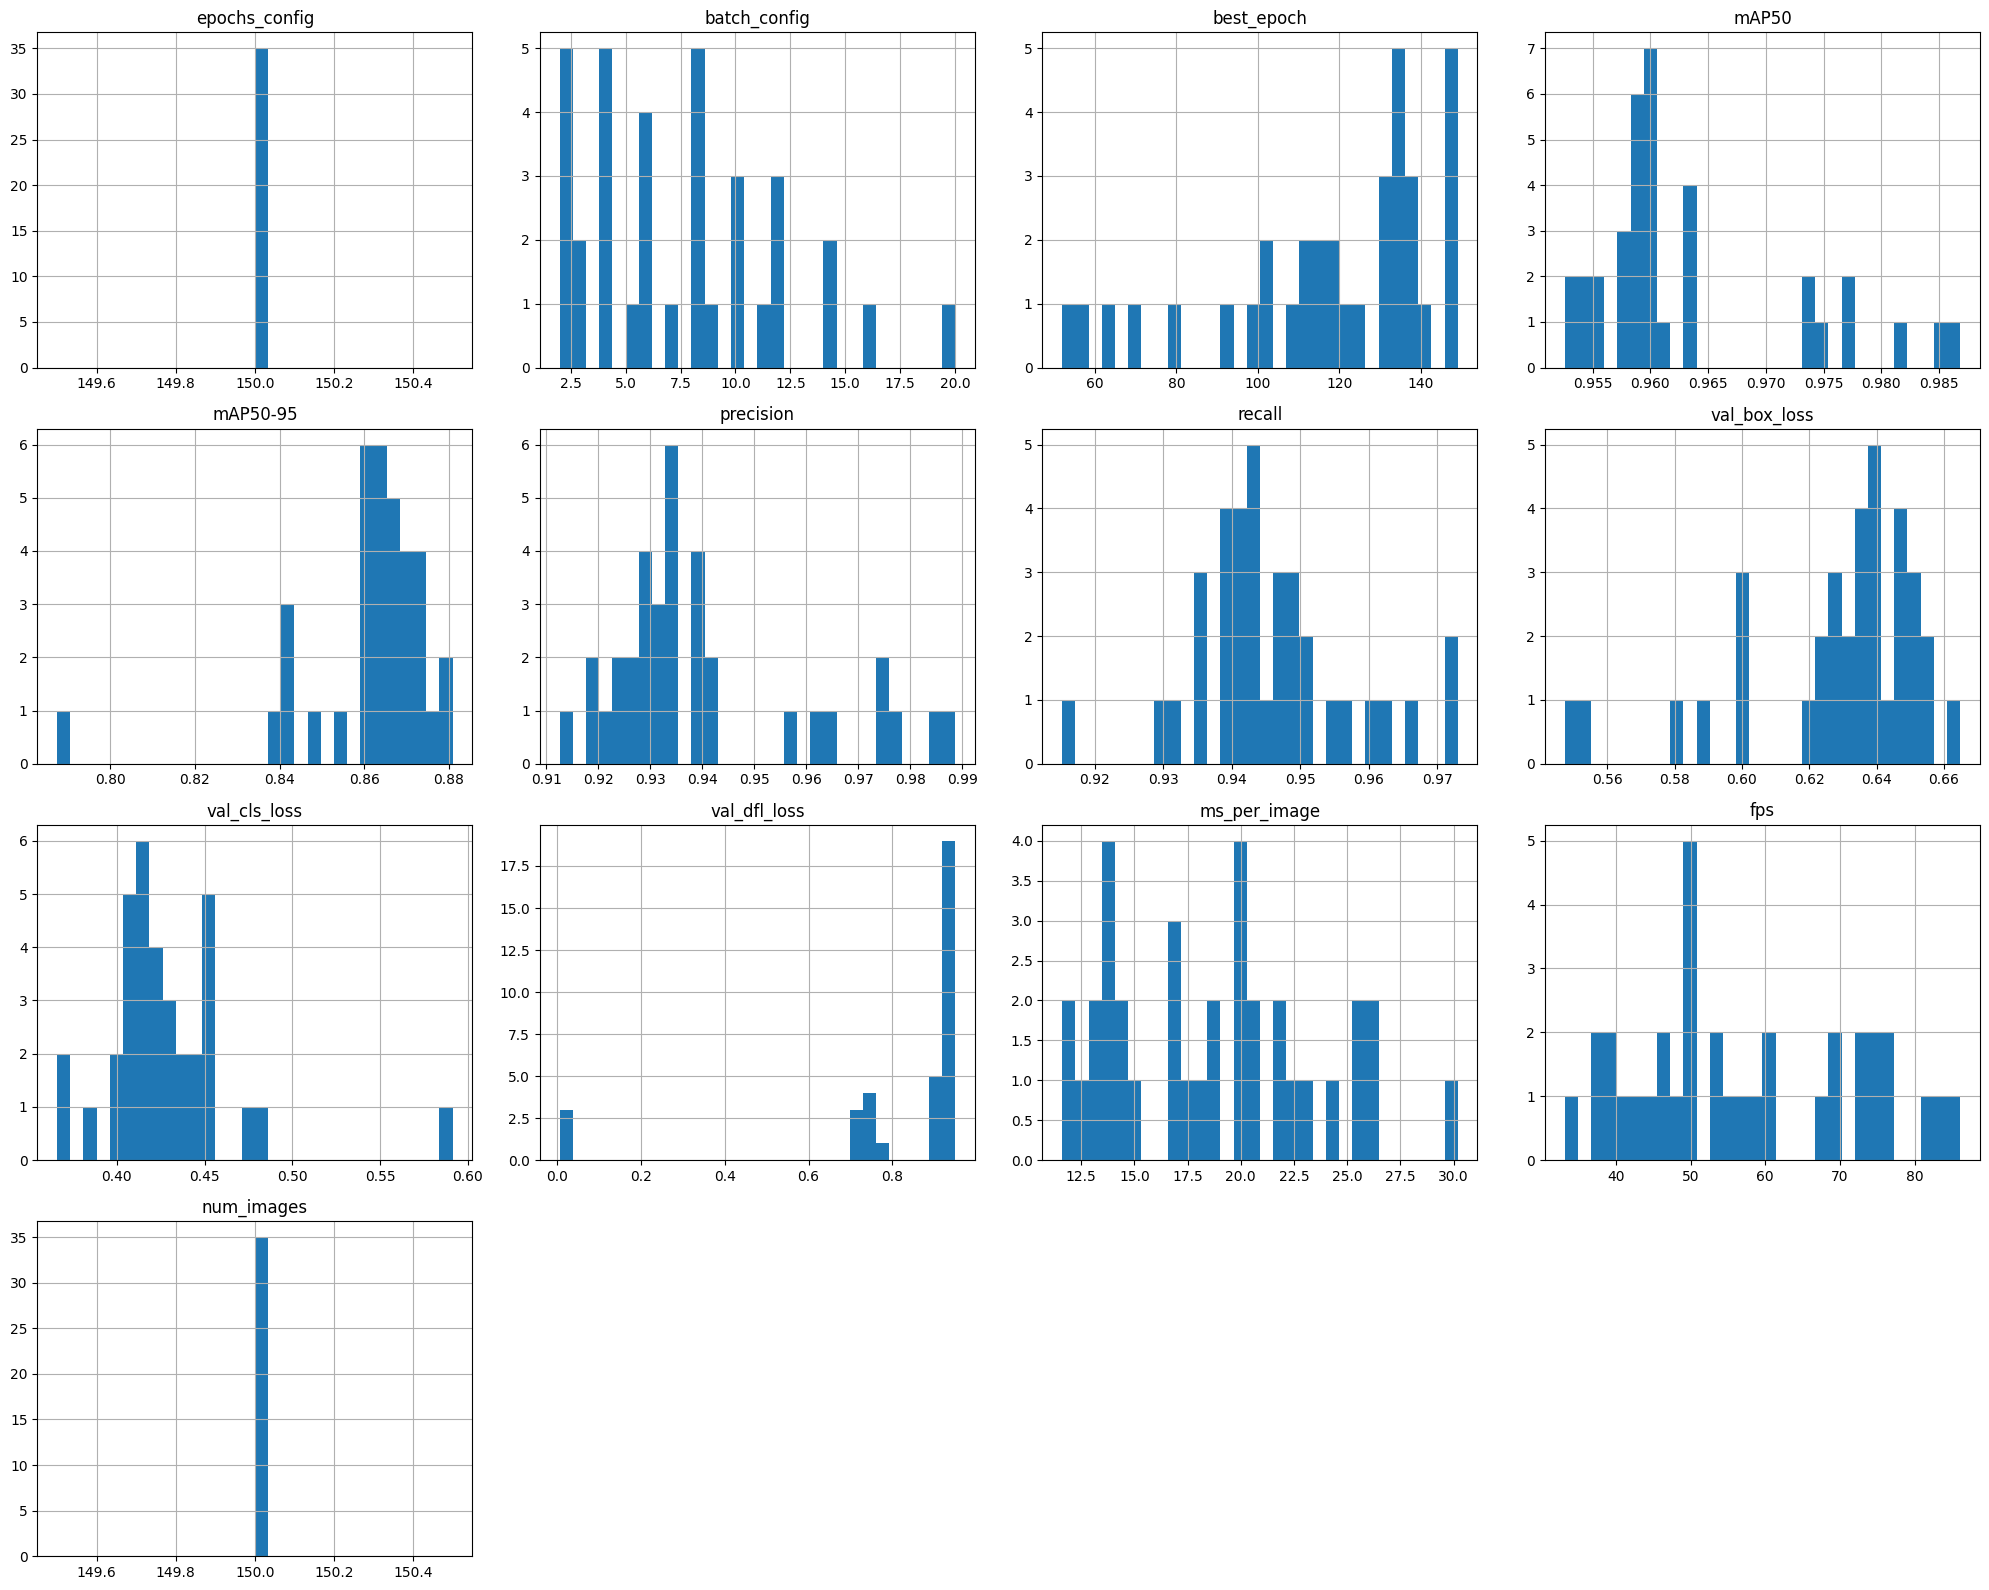

In [67]:
df_yolo[numeric_cols_yolo].hist(figsize=(20,16), bins=30)
plt.tight_layout()
plt.show()

#### 1.2.2 YOLO benchmark chart

In [68]:
def plot_yolo_vs_batch(df, y_col, x_col="batch_config", title=None, df_name=None):
    """
    Plota benchmark YOLO:
    X -> coluna escolhida (x_col)
    Y -> coluna escolhida (y_col)
    Linha -> yolo_version
    """

    # ordenar pelos valores de X
    df_plot = df.sort_values(x_col)

    plt.figure(figsize=(11, 6))

    # linhas por versão YOLO
    for version, group in df_plot.groupby("yolo_version"):
        plt.plot(
            group[x_col],
            group[y_col],
            marker="o",
            markersize=7,
            linewidth=2.5,
            label=version
        )

    # --- ticks discretos se X for inteiro ---
    if pd.api.types.is_numeric_dtype(df_plot[x_col]):
        xmin = df_plot[x_col].min()
        xmax = df_plot[x_col].max()

        # só faz ticks 1-a-1 se parecer inteiro
        if float(xmin).is_integer() and float(xmax).is_integer():
            plt.xticks(np.arange(int(xmin), int(xmax) + 1, 1))

    # --- limites Y bonitos ---
    ymin = df_plot[y_col].min()
    ymax = df_plot[y_col].max()
    margin = (ymax - ymin) * 0.05 if ymax != ymin else 0.01
    plt.ylim(ymin - margin, ymax + margin)

    # labels
    plt.xlabel(x_col, fontsize=12)
    plt.ylabel(y_col, fontsize=12)

    # título automático
    if title is None:
        base = f"YOLO Benchmark: {y_col} vs {x_col}"
        title = f"{base} ({df_name})" if df_name else base

    plt.title(title, fontsize=14, weight="bold")

    plt.grid(True, linestyle="--", alpha=0.3)
    plt.legend(title="YOLO version")

    plt.tight_layout()
    plt.show()


mAP50-95 vs batch

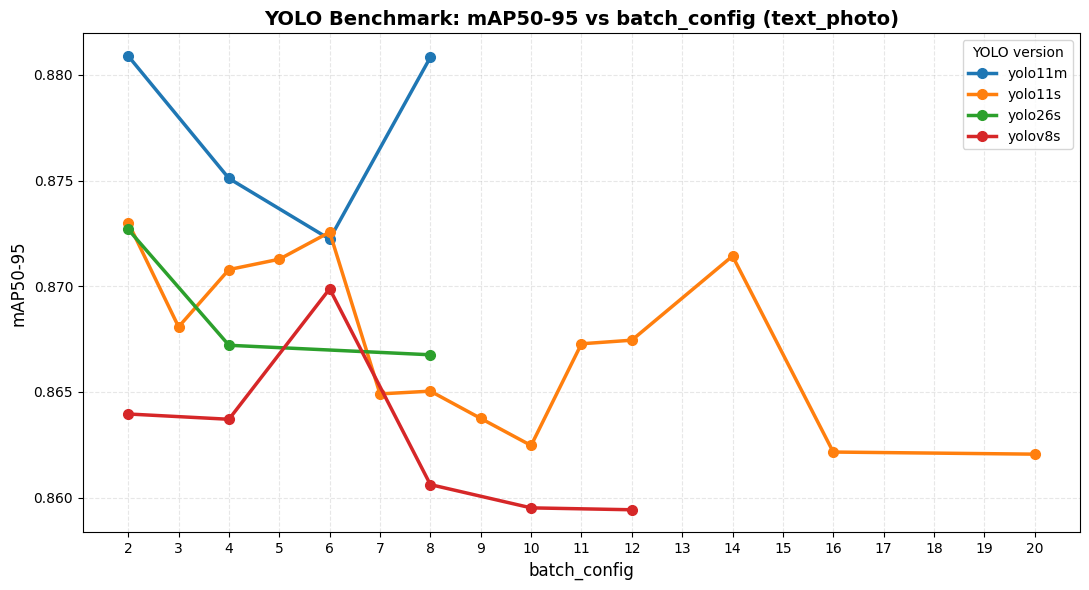

In [69]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50-95", df_name= "text_photo")

mAP50 vs batch

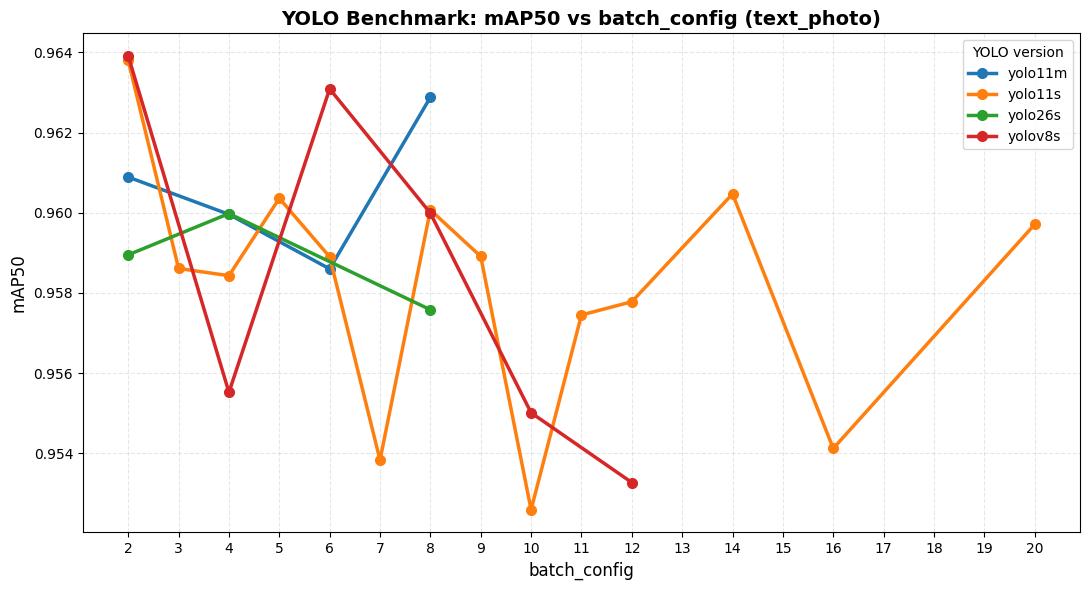

In [70]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50", df_name= "text_photo")

Precision vs batch

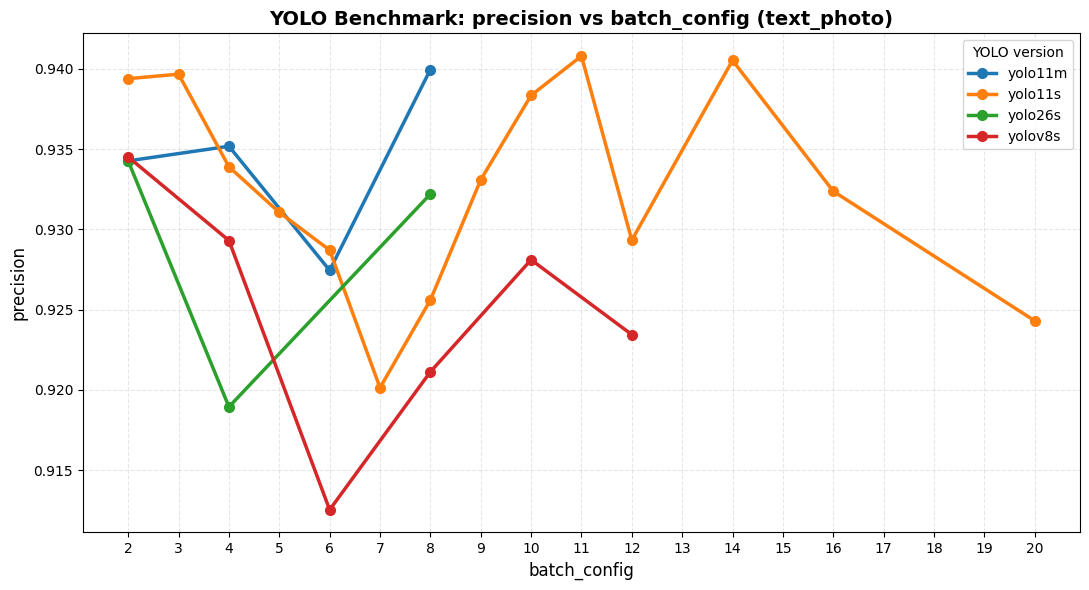

In [71]:
plot_yolo_vs_batch(df_yolo_text_photo, "precision", df_name= "text_photo")

Recall vs batch

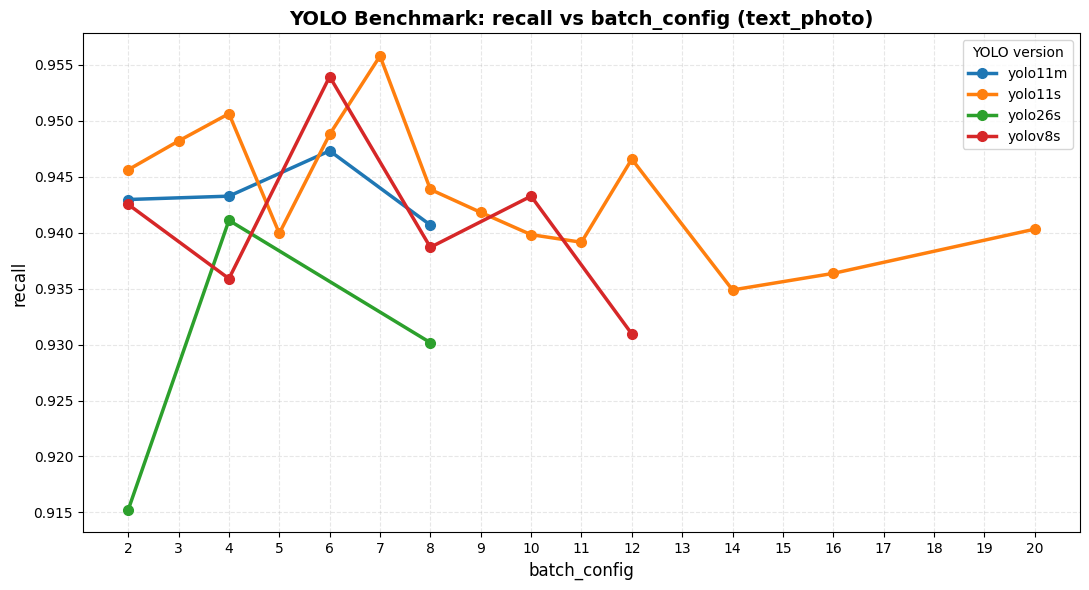

In [72]:
plot_yolo_vs_batch(df_yolo_text_photo, "recall", df_name= "text_photo")

Val_box_loss vs batch

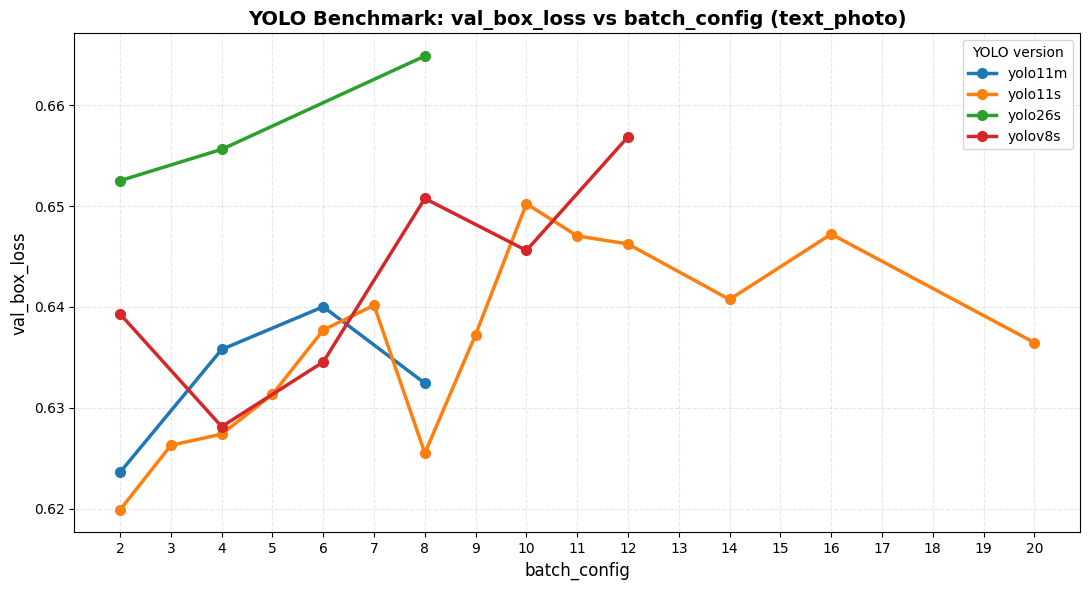

In [73]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_box_loss", df_name= "text_photo")

Val_cls_loss vs batch

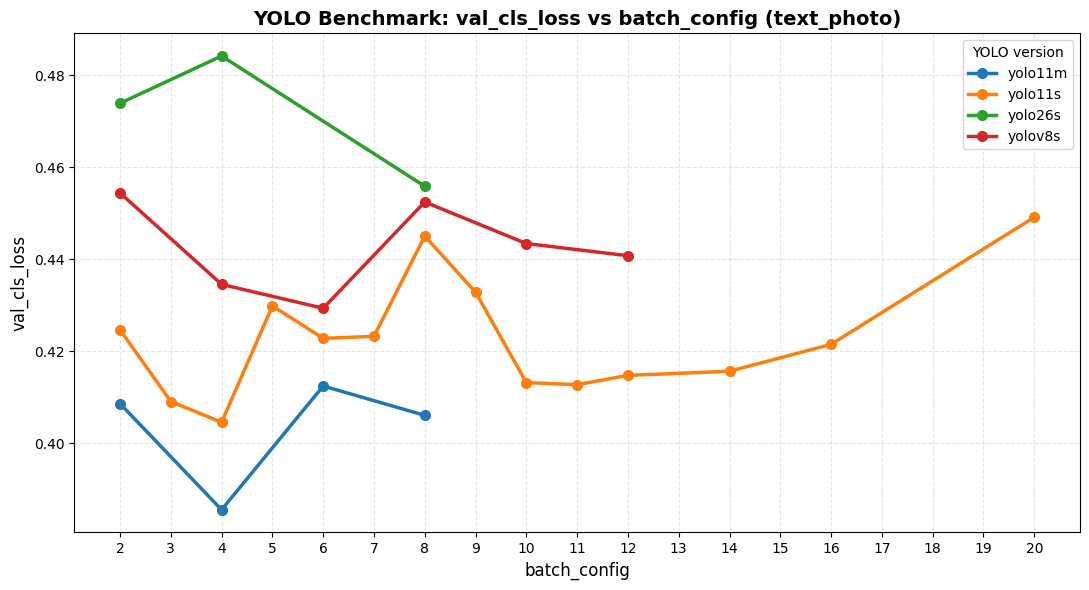

In [74]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_cls_loss", df_name= "text_photo")

Val_dfl_loss vs batch

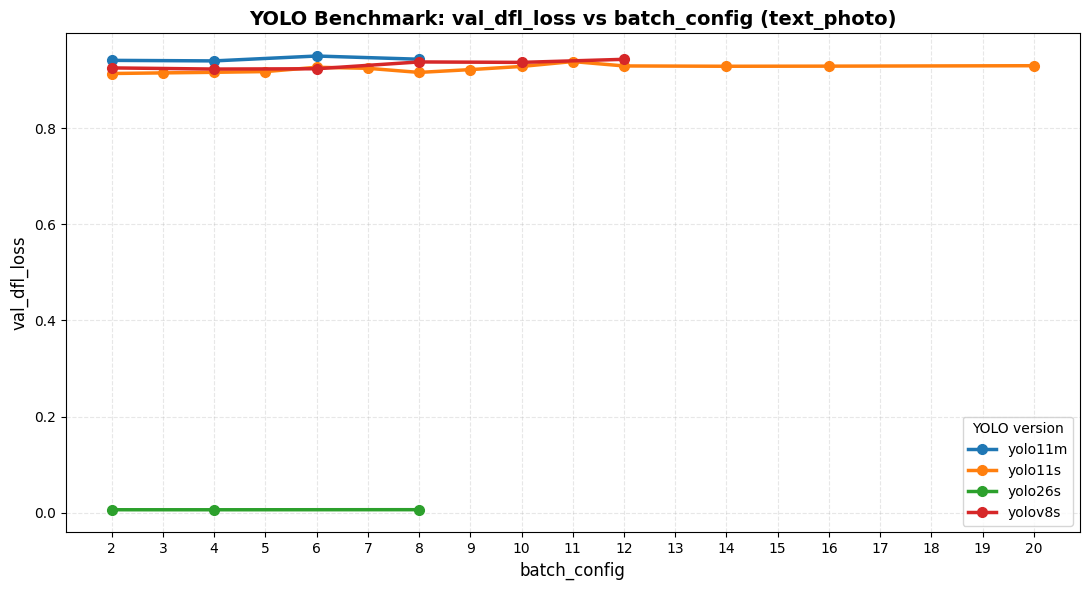

In [75]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_dfl_loss", df_name= "text_photo")

FPS vs batch

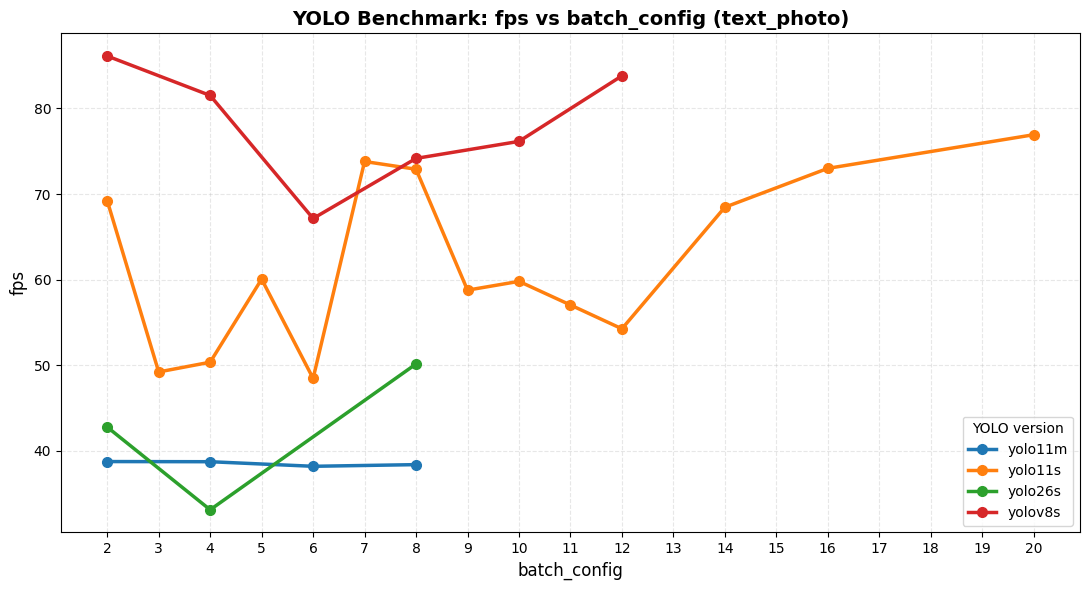

In [76]:
plot_yolo_vs_batch(df_yolo_text_photo, "fps", df_name= "text_photo")

Ms_per_image vs batch

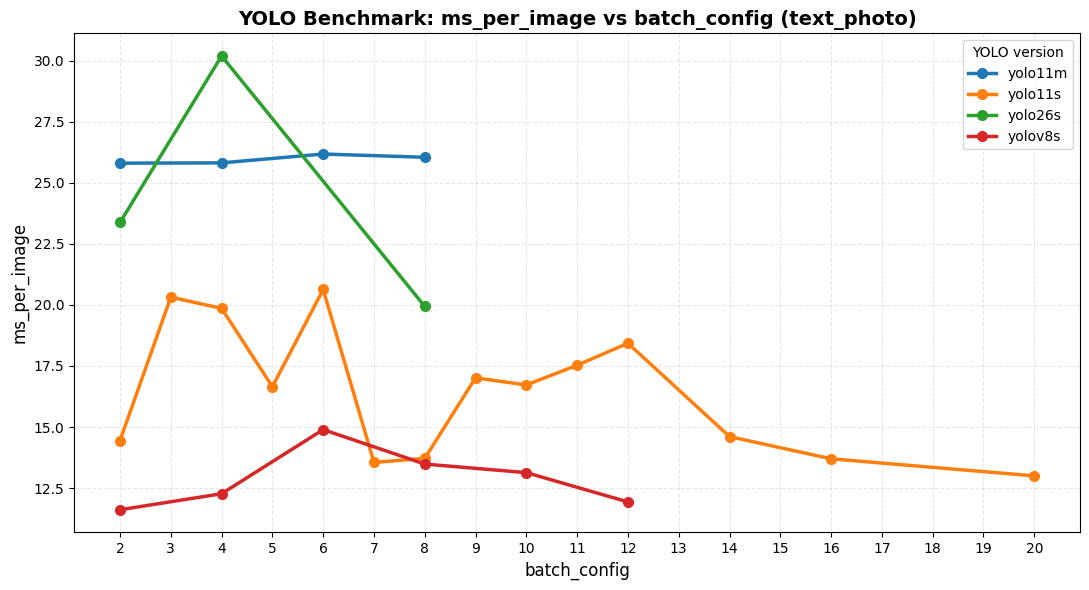

In [77]:
plot_yolo_vs_batch(df_yolo_text_photo, "ms_per_image", df_name= "text_photo")

mAP50-95 vs ms_per_image

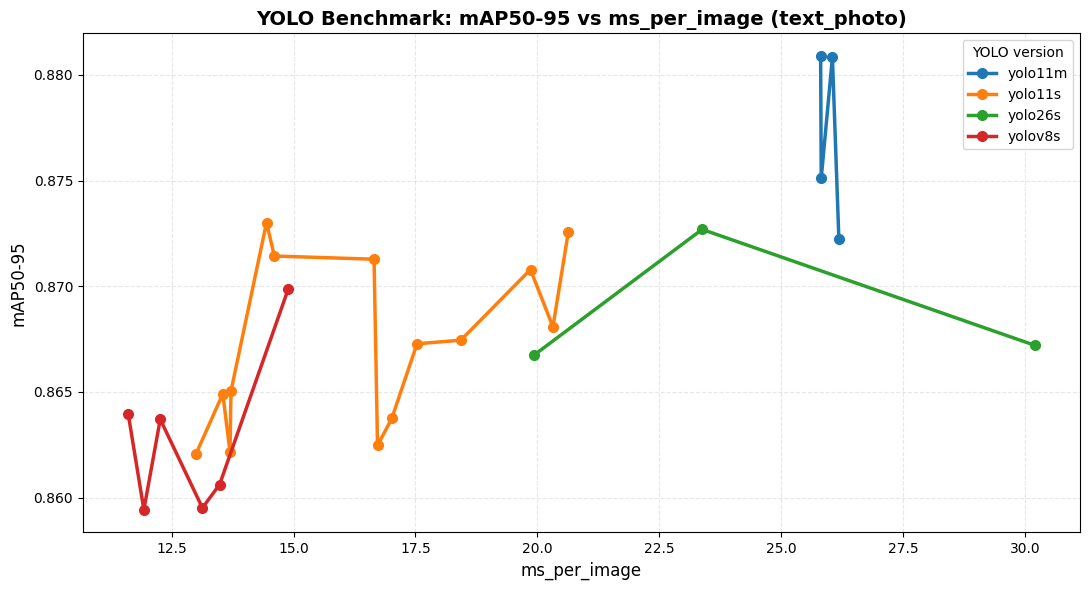

In [78]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50-95", "ms_per_image", df_name= "text_photo")

mAP50 vs ms_per_image

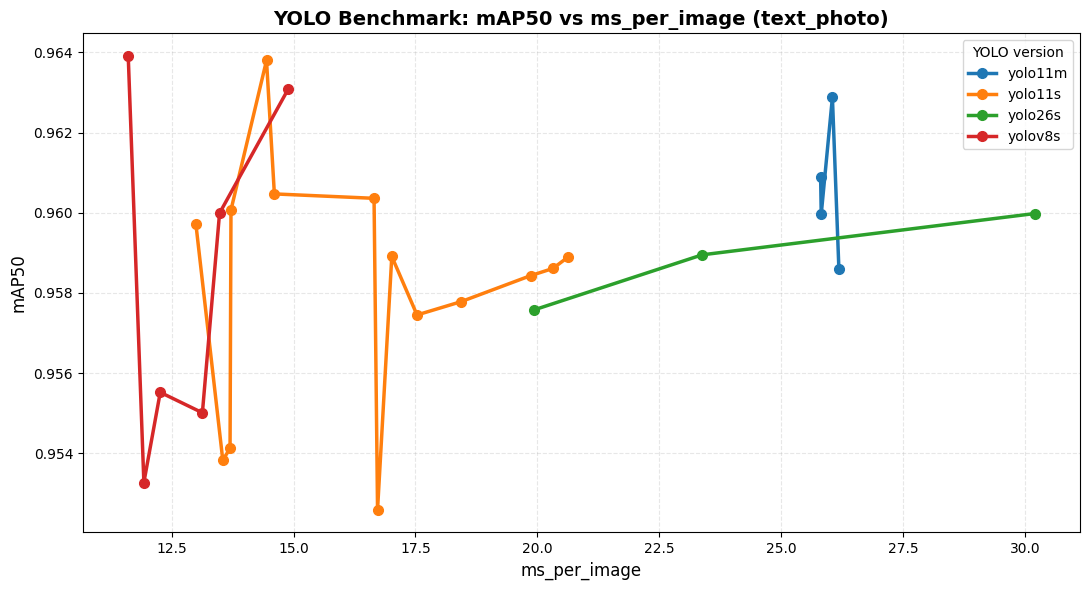

In [79]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50","ms_per_image", df_name= "text_photo")

Precision vs ms_per_image

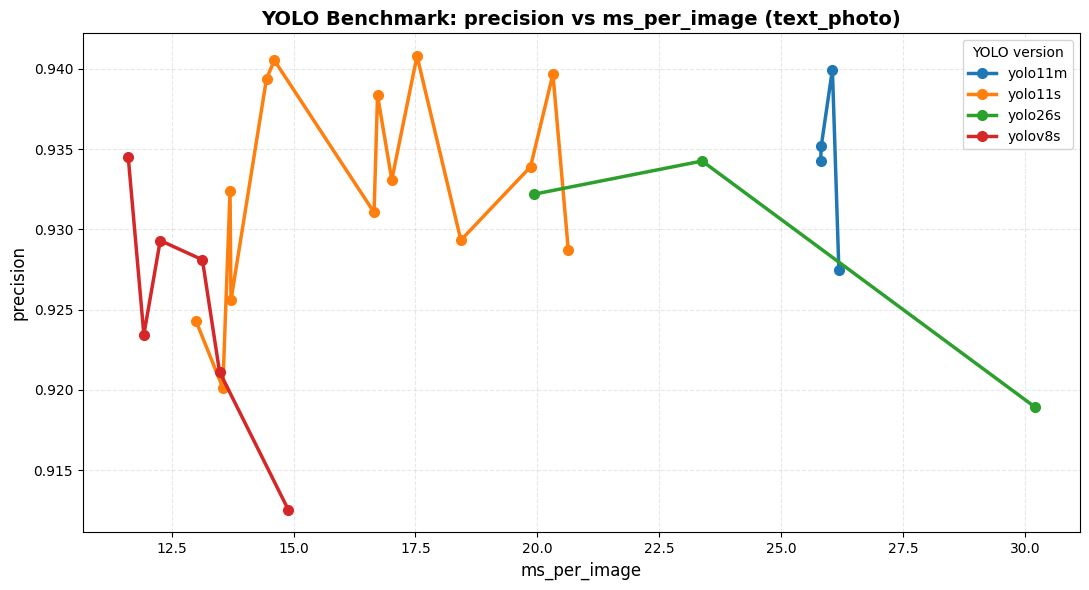

In [80]:
plot_yolo_vs_batch(df_yolo_text_photo, "precision", "ms_per_image",df_name= "text_photo")

Recall vs ms_per_image

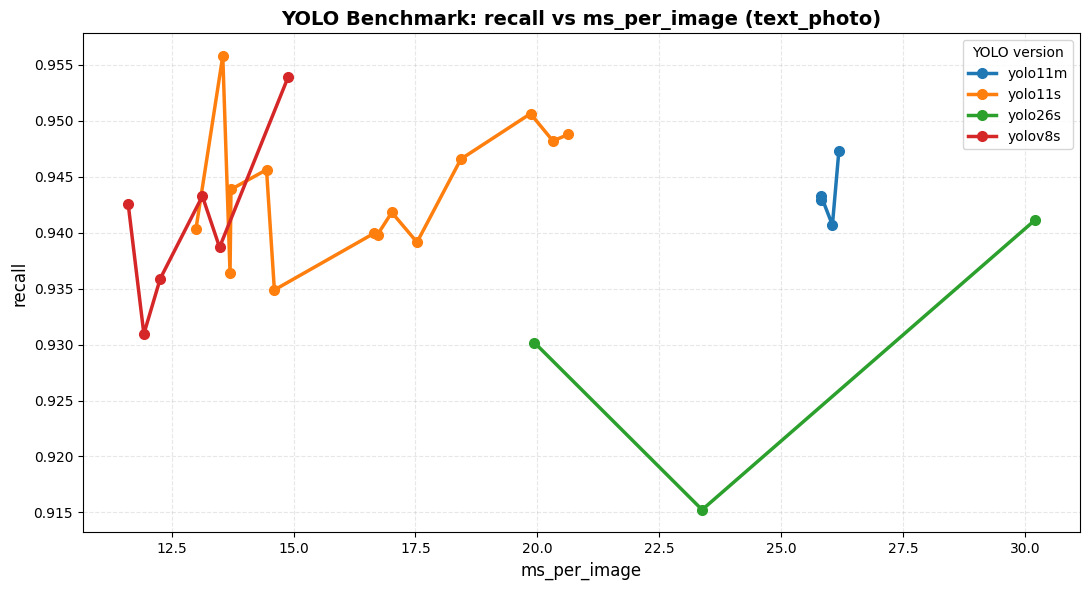

In [81]:
plot_yolo_vs_batch(df_yolo_text_photo, "recall", "ms_per_image",df_name= "text_photo")

Val_box_loss vs ms_per_image

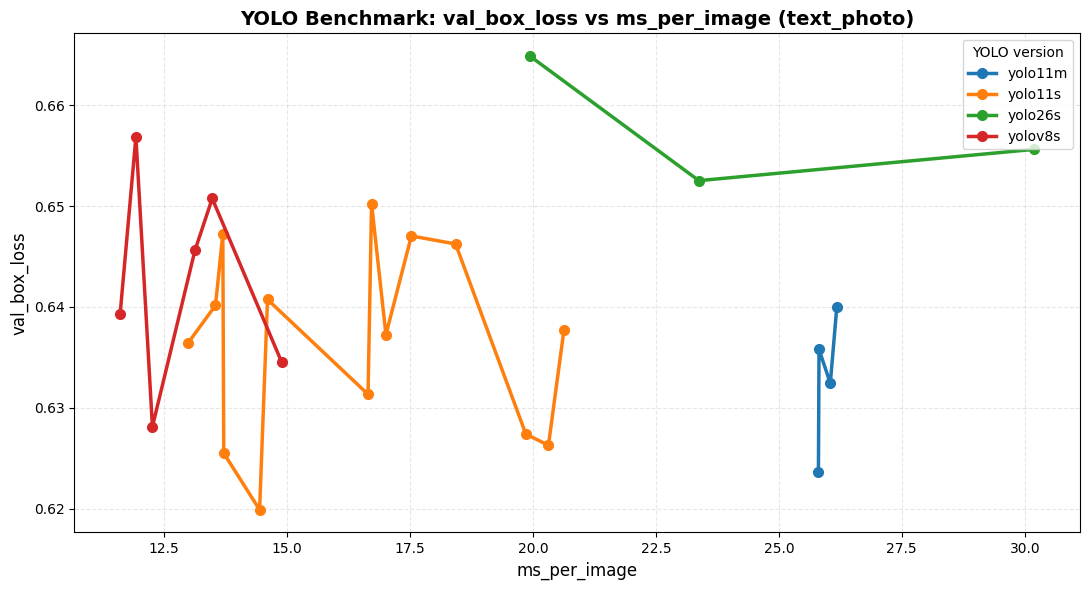

In [82]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_box_loss","ms_per_image",df_name= "text_photo")

Val_cls_loss vs ms_per_image

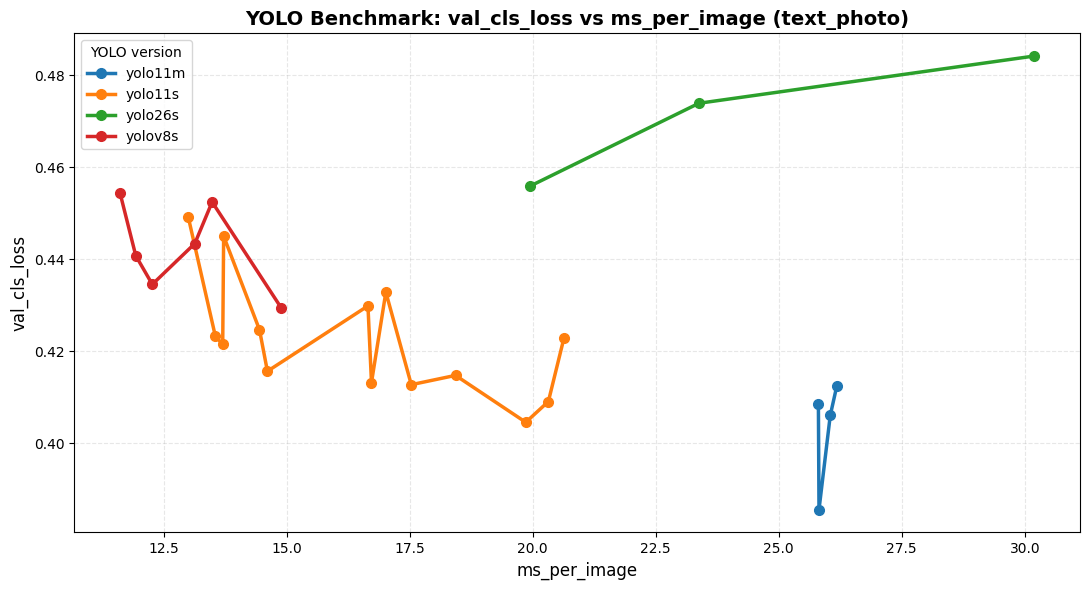

In [83]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_cls_loss", "ms_per_image",df_name= "text_photo")

Val_dfl_loss vs ms_per_image

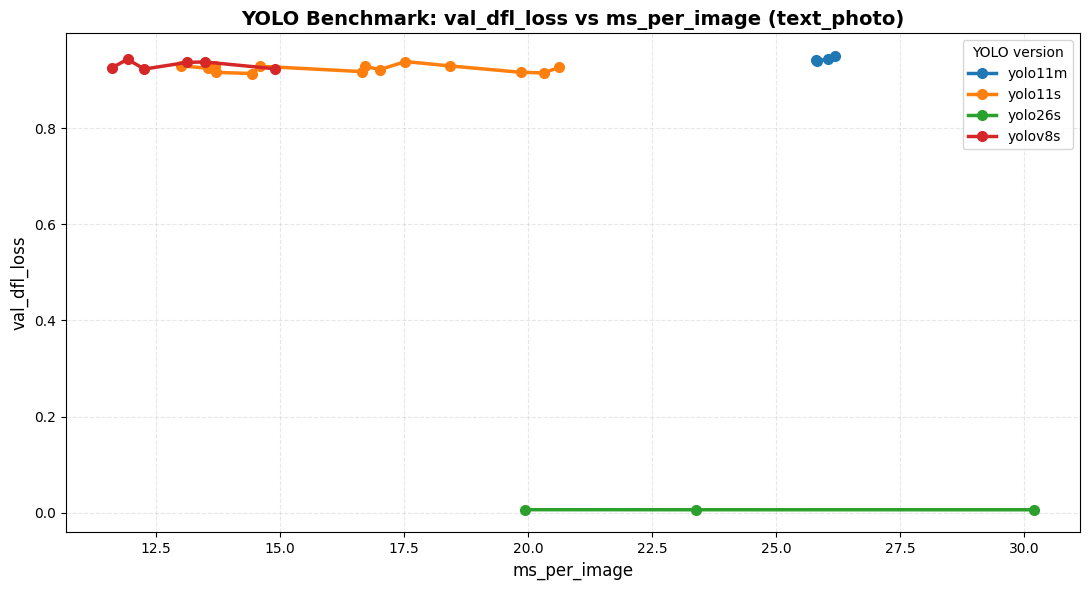

In [84]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_dfl_loss", "ms_per_image",df_name= "text_photo")

#### 1.2.2 YOLO benchmark ordered bar chart

In [123]:
def plot_sorted_bar(
    df,
    y_col,
    group_col="yolo_version",
    title=None,
    df_name=None,
    ascending=True,
    agg_func="max",
    figsize=(5, 5)
):
    """
    Gráfico de barras ordenado com:
    - 1 valor por modelo (agregação)
    - cores diferentes por barra

    Parâmetros:
    - agg_func: "max", "mean", "min", etc.
    """

    # --- garantir 1 valor por modelo ---
    df_grouped = (
        df.groupby(group_col)[y_col]
        .agg(agg_func)
        .reset_index()
    )

    # --- ordenar ---
    df_plot = df_grouped.sort_values(y_col, ascending=ascending)

    plt.figure(figsize=figsize)

    # --- cores diferentes ---
    colors = plt.cm.tab20(np.linspace(0, 1, len(df_plot)))

    plt.bar(df_plot[group_col].astype(str), df_plot[y_col], color=colors)

    # labels
    plt.xlabel(group_col, fontsize=12)
    plt.ylabel(y_col, fontsize=12)

    # título automático
    if title is None:
        base = f"{y_col} ({agg_func}) ordered by {group_col}"
        title = f"{base} ({df_name})" if df_name else base

    plt.title(title, fontsize=14, weight="bold")

    # rodar labels
    plt.xticks(rotation=45, ha="right")

    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()



mAP50-95

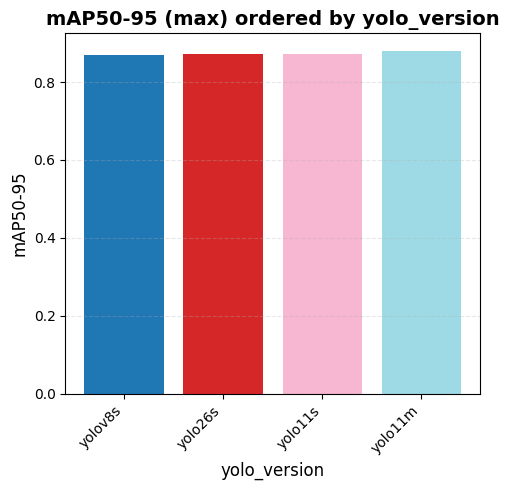

In [124]:
plot_sorted_bar(df_yolo_text_photo, "mAP50-95", group_col="yolo_version")


mAP50

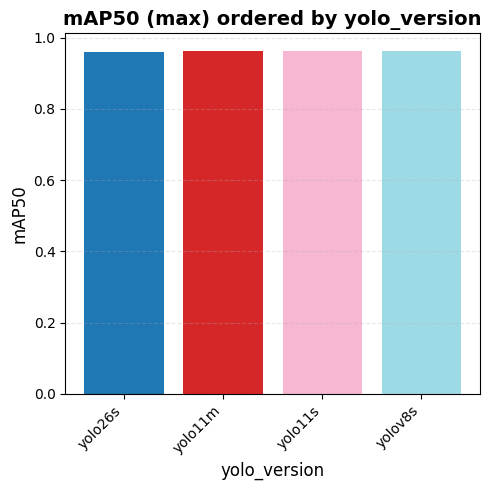

In [125]:
plot_sorted_bar(df_yolo_text_photo, "mAP50", group_col="yolo_version")

Precision

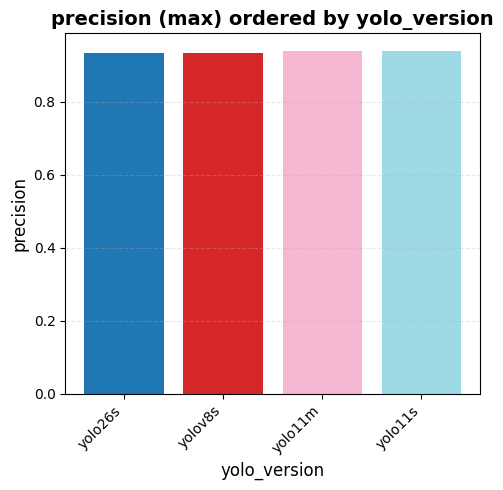

In [126]:
plot_sorted_bar(df_yolo_text_photo, "precision", group_col="yolo_version")

Recall

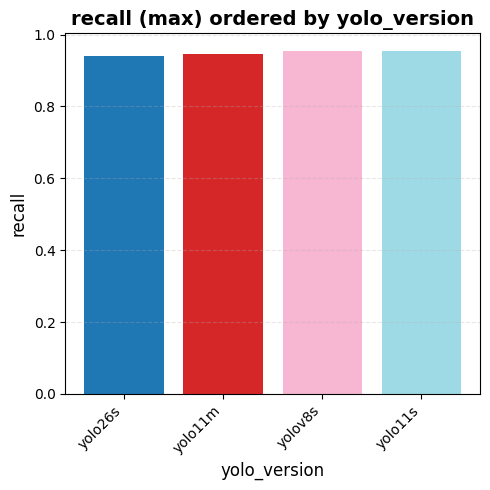

In [127]:
plot_sorted_bar(df_yolo_text_photo, "recall", group_col="yolo_version")

Val_box_loss

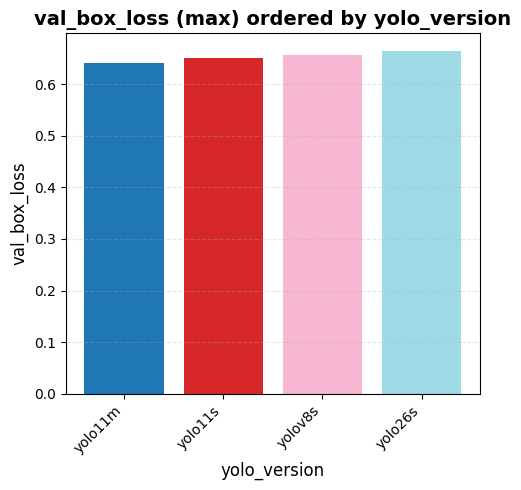

In [128]:
plot_sorted_bar(df_yolo_text_photo, "val_box_loss", group_col="yolo_version")

Val_cls_loss

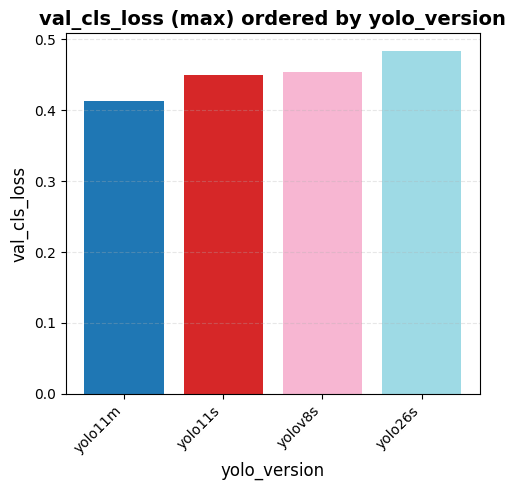

In [129]:
plot_sorted_bar(df_yolo_text_photo, "val_cls_loss", group_col="yolo_version")

Val_dfl_loss

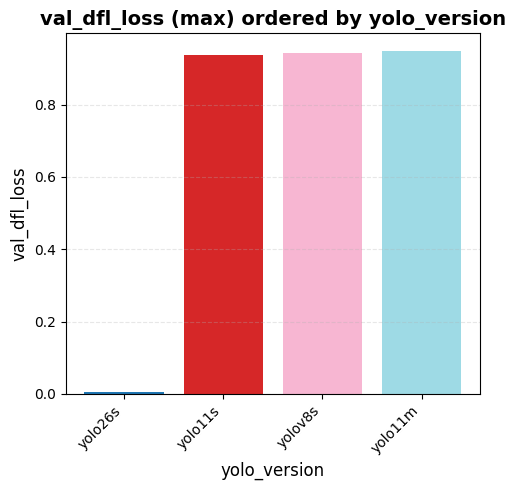

In [130]:
plot_sorted_bar(df_yolo_text_photo, "val_dfl_loss", group_col="yolo_version")

FPS

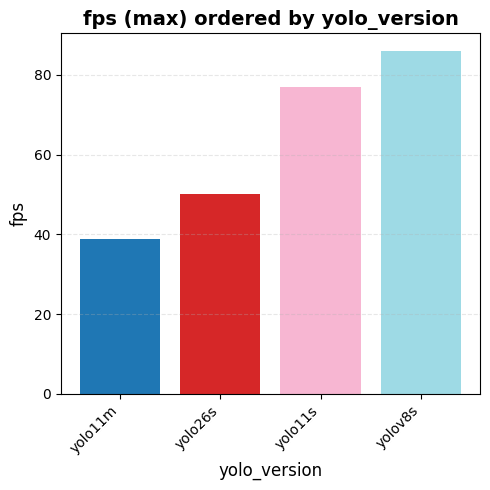

In [131]:
plot_sorted_bar(df_yolo_text_photo, "fps", group_col="yolo_version")

Ms_per_image

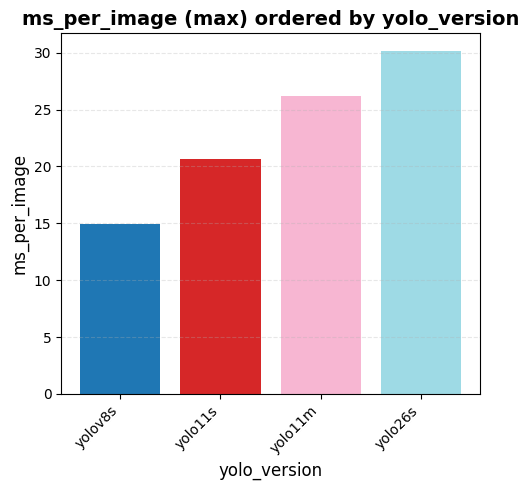

In [132]:
plot_sorted_bar(df_yolo_text_photo, "ms_per_image", group_col="yolo_version")

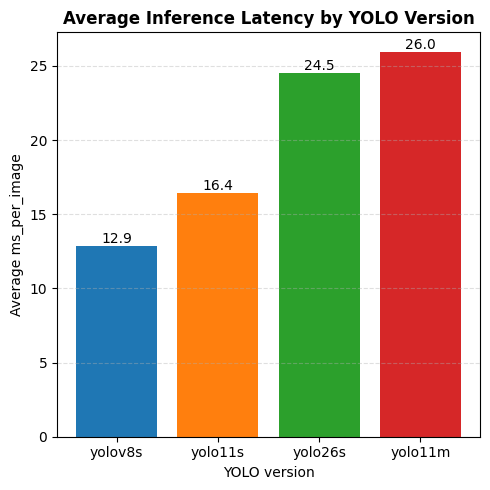

In [137]:
def plot_avg_latency_by_yolo(df):
    """
    Bar plot da latência média (ms_per_image) por versão YOLO,
    com cores diferentes para cada modelo.
    """

    # média por modelo
    df_avg = (
        df.groupby("yolo_version")["ms_per_image"]
        .mean()
        .sort_values()
    )

    plt.figure(figsize=(5, 5))

    # cores distintas
    colors = plt.cm.tab10(range(len(df_avg)))

    bars = plt.bar(
        df_avg.index,
        df_avg.values,
        color=colors
    )

    plt.ylabel("Average ms_per_image")
    plt.xlabel("YOLO version")
    plt.title("Average Inference Latency by YOLO Version", weight="bold")

    plt.grid(axis="y", linestyle="--", alpha=0.4)

    # valores em cima das barras
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.1f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()

plot_avg_latency_by_yolo(df_yolo_text_photo)


#### 1.2.3 Extra YOLO graphs

In [96]:
def plot_yolo_vs_batch(
    df,
    y_col,
    x_col="ms_per_image",
    label_col="batch_config",
    title=None,
    df_name=None
):
    """
    YOLO benchmark:
    X -> métrica (ex: ms_per_image)
    Y -> métrica (ex: mAP50-95)
    Linha -> yolo_version
    Texto do ponto -> batch_config
    """

    df_plot = df.sort_values(x_col)

    plt.figure(figsize=(11, 6))

    for version, group in df_plot.groupby("yolo_version"):
        plt.plot(
            group[x_col],
            group[y_col],
            marker="o",
            markersize=7,
            linewidth=2.5,
            label=version
        )

        # --- anotar batch em cada ponto ---
        for _, row in group.iterrows():
            plt.text(
                row[x_col],
                row[y_col],
                f"b{row[label_col]}",
                fontsize=9,
                ha="left",
                va="bottom",
                alpha=0.8
            )

    # limites Y
    ymin = df_plot[y_col].min()
    ymax = df_plot[y_col].max()
    margin = (ymax - ymin) * 0.05 if ymax != ymin else 0.01
    plt.ylim(ymin - margin, ymax + margin)

    plt.xlabel(x_col, fontsize=12)
    plt.ylabel(y_col, fontsize=12)

    if title is None:
        base = f"YOLO Benchmark: {y_col} vs {x_col}"
        title = f"{base} ({df_name})" if df_name else base

    plt.title(title, fontsize=14, weight="bold")

    plt.grid(True, linestyle="--", alpha=0.3)
    plt.legend(title="YOLO version")

    plt.tight_layout()
    plt.show()


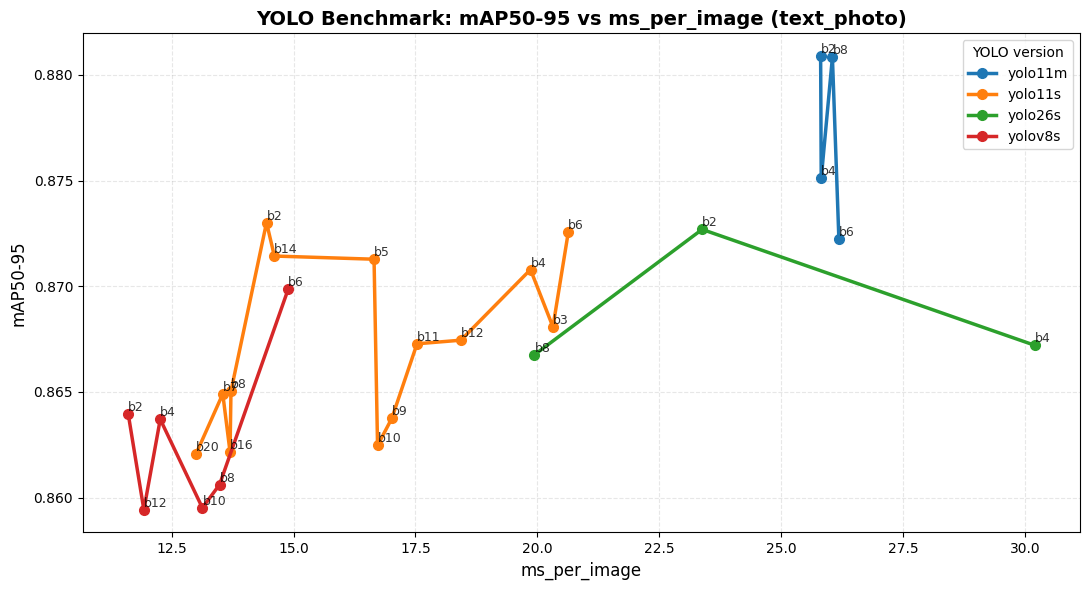

In [97]:
plot_yolo_vs_batch(
    df_yolo_text_photo,
    y_col="mAP50-95",
    x_col="ms_per_image",
    label_col="batch_config",
    df_name="text_photo"
)


In [ ]:
import matplotlib.cm as cm


def plot_yolo_batch_colors(
    df,
    y_col="mAP50-95",
    x_col="ms_per_image",
    batch_col="batch_config",
    title=None,
    df_name=None
):
    df_plot = df.sort_values(x_col)

    plt.figure(figsize=(10, 6))

    # cores distintas para cada batch
    unique_batches = sorted(df_plot[batch_col].unique())
    cmap = cm.get_cmap("tab10", len(unique_batches))

    batch_color_map = {
        batch: cmap(i) for i, batch in enumerate(unique_batches)
    }

    for version, group in df_plot.groupby("yolo_version"):

        # linha da arquitetura
        plt.plot(
            group[x_col],
            group[y_col],
            linewidth=2,
            alpha=0.6,
            label=version
        )

        # pontos coloridos por batch
        for batch in unique_batches:
            subset = group[group[batch_col] == batch]
            if not subset.empty:
                plt.scatter(
                    subset[x_col],
                    subset[y_col],
                    color=batch_color_map[batch],
                    s=70,
                    edgecolors="black",
                    linewidth=0.5,
                    alpha=0.9
                )

    # legenda separada para batches
    handles = [
        plt.Line2D([0], [0],
                   marker='o',
                   color='w',
                   markerfacecolor=batch_color_map[b],
                   markeredgecolor="black",
                   markersize=8,
                   label=f"Batch {b}")
        for b in unique_batches
    ]

    plt.legend(title="YOLO version", loc="lower right")
    plt.gca().add_artist(plt.legend(handles=handles, title="Batch", loc="upper left"))

    # limites Y
    ymin, ymax = df_plot[y_col].min(), df_plot[y_col].max()
    margin = (ymax - ymin) * 0.05 if ymax != ymin else 0.01
    plt.ylim(ymin - margin, ymax + margin)

    plt.xlabel("Latency (ms per image)", fontsize=12)
    plt.ylabel("mAP50–95", fontsize=12)

    if title is None:
        base = "YOLO Performance vs Latency"
        title = f"{base} ({df_name})" if df_name else base

    plt.title(title, fontsize=14, weight="bold")

    plt.grid(True, linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()


C:\Users\danie\AppData\Local\Temp\ipykernel_16316\1956799324.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab10", len(unique_batches))


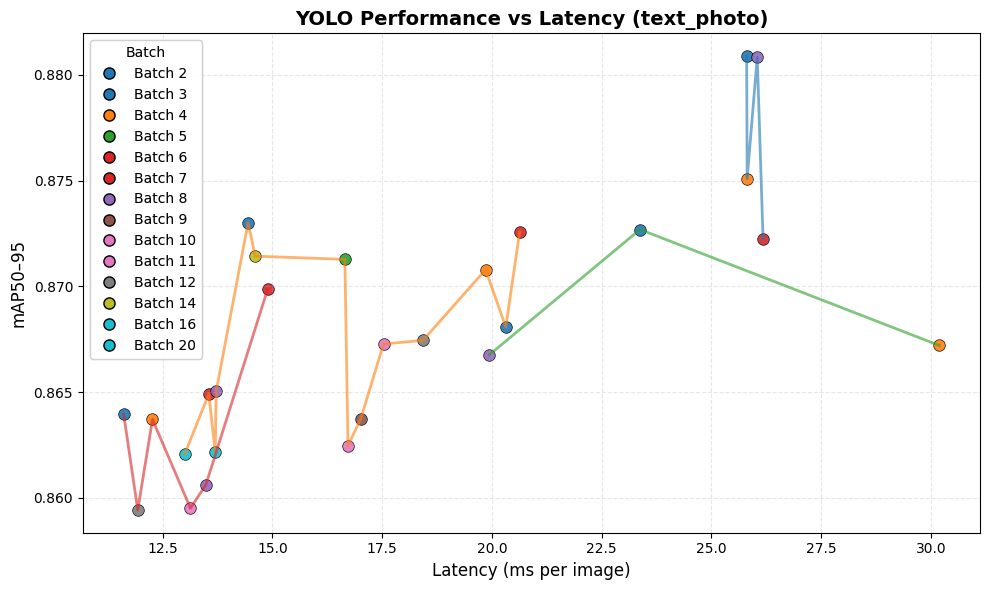

In [102]:
plot_yolo_batch_colors(df_yolo_text_photo, df_name="text_photo")


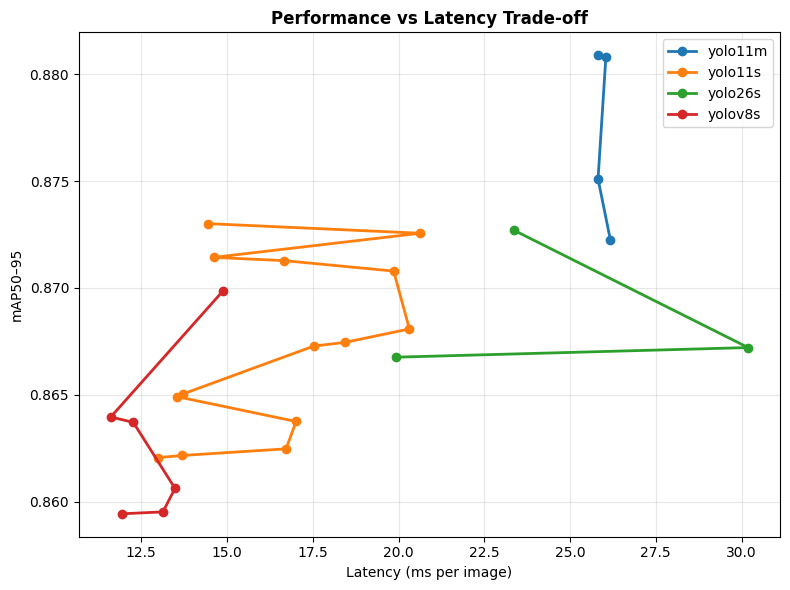

In [107]:
def plot_map_vs_latency(df):

    plt.figure(figsize=(8,6))

    for version, group in df.groupby("yolo_version"):
        plt.plot(
            group["ms_per_image"],
            group["mAP50-95"],
            marker="o",
            linewidth=2,
            label=version
        )

    plt.xlabel("Latency (ms per image)")
    plt.ylabel("mAP50–95")
    plt.title("Performance vs Latency Trade-off", weight="bold")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_map_vs_latency(df_yolo_text_photo)

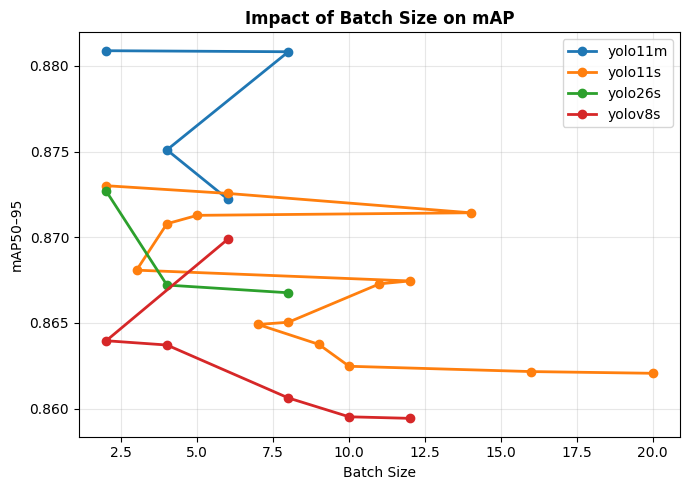

In [108]:
def plot_batch_vs_map(df):

    plt.figure(figsize=(7,5))

    for version, group in df.groupby("yolo_version"):
        plt.plot(
            group["batch_config"],
            group["mAP50-95"],
            marker="o",
            linewidth=2,
            label=version
        )

    plt.xlabel("Batch Size")
    plt.ylabel("mAP50–95")
    plt.title("Impact of Batch Size on mAP", weight="bold")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_batch_vs_map(df_yolo_text_photo)

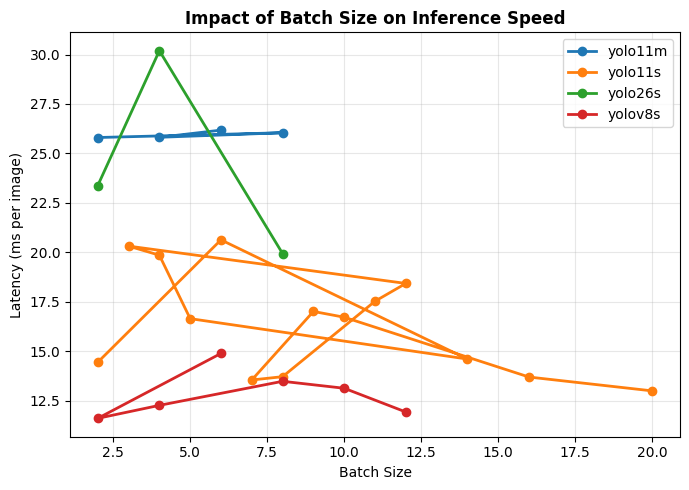

In [109]:
def plot_batch_vs_speed(df):

    plt.figure(figsize=(7,5))

    for version, group in df.groupby("yolo_version"):
        plt.plot(
            group["batch_config"],
            group["ms_per_image"],
            marker="o",
            linewidth=2,
            label=version
        )

    plt.xlabel("Batch Size")
    plt.ylabel("Latency (ms per image)")
    plt.title("Impact of Batch Size on Inference Speed", weight="bold")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_batch_vs_speed(df_yolo_text_photo)

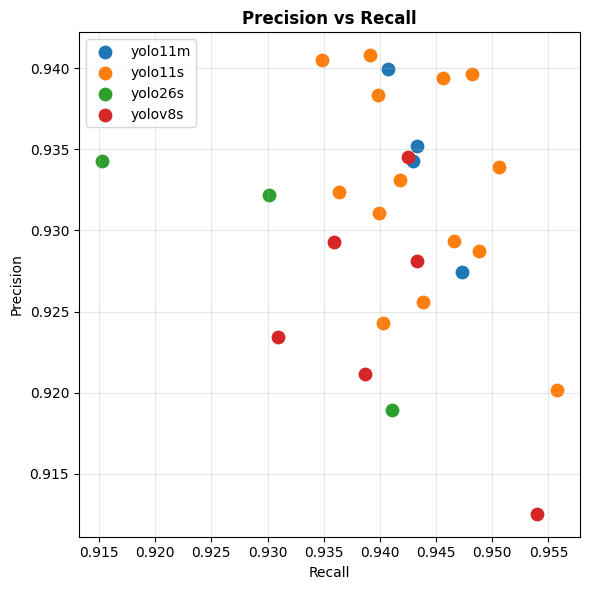

In [110]:
def plot_precision_vs_recall(df):

    plt.figure(figsize=(6,6))

    for version, group in df.groupby("yolo_version"):
        plt.scatter(
            group["recall"],
            group["precision"],
            s=80,
            label=version
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision vs Recall", weight="bold")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_precision_vs_recall(df_yolo_text_photo)

In [162]:
import matplotlib.pyplot as plt


def plot_precision_vs_recall_mean(df):
    """
    Scatter plot Precision vs Recall usando médias por YOLO,
    com cores fixas por modelo e escala ampla (0.91–0.96).
    """

    df_mean = (
        df.groupby("yolo_version")[["precision", "recall"]]
        .mean()
        .reset_index()
    )

    # 🔹 Mapa fixo de cores
    color_map = {
        "yolov8s": "blue",
        "yolo11s": "orange",
        "yolo26s": "green",
        "yolo11m": "red"
    }

    plt.figure(figsize=(5, 5))

    for _, row in df_mean.iterrows():
        plt.scatter(
            row["recall"],
            row["precision"],
            s=150,
            color=color_map.get(row["yolo_version"], "gray"),
            edgecolors="black",
            linewidth=0.8,
            label=row["yolo_version"]
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Mean Precision vs Recall by YOLO Version", weight="bold")

    plt.xlim(0.91, 0.96)
    plt.ylim(0.91, 0.96)

    plt.grid(alpha=0.3)

    plt.legend(
        title="YOLO version",
        loc="upper left",
        frameon=True
    )

    plt.tight_layout()
    plt.show()


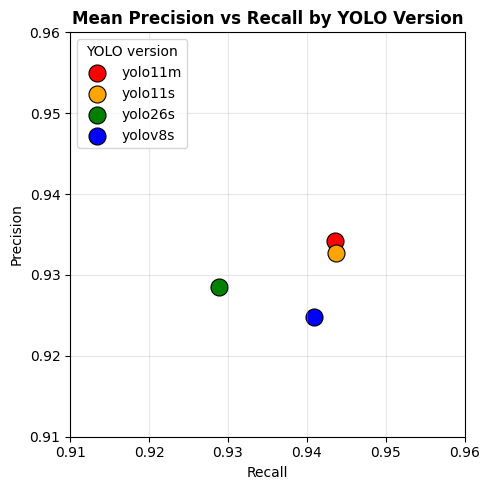

In [163]:
plot_precision_vs_recall_mean(df_yolo_text_photo)


In [211]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm


def plot_yolo11s_map_vs_latency(df, v1, v2, v3, v4):
    """
    Scatter plot mAP50-95 vs ms_per_image
    apenas para yolo11s,
    com cores bem distinguíveis por batch.
    """

    df_11s = df[df["yolo_version"] == "yolo11s"].copy()
    df_11s = df_11s.sort_values("batch_config")

    plt.figure(figsize=(6, 5))

    unique_batches = sorted(df_11s["batch_config"].unique())

    # usar tab20 para cores bem separadas
    cmap = cm.get_cmap("tab20", len(unique_batches))

    for i, batch in enumerate(unique_batches):
        subset = df_11s[df_11s["batch_config"] == batch]

        plt.scatter(
            subset["ms_per_image"],
            subset["mAP50-95"],
            s=130,
            color=cmap(i),
            edgecolors="black",
            linewidth=0.9,
            label=f"Batch {batch}"
        )

    plt.xlabel("Latency (ms per image)")
    plt.ylabel("mAP50–95")
    plt.title("YOLO11s: mAP50–95 vs Latency (by Batch) - Model skill_table", weight="bold")

    plt.xlim(v1, v2)
    plt.ylim(v3, v4)

    plt.grid(alpha=0.3)

    plt.legend(
        title="Batch",
        bbox_to_anchor=(1.02, 1),   # legenda fora do gráfico
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()


C:\Users\danie\AppData\Local\Temp\ipykernel_16316\2173746210.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab20", len(unique_batches))


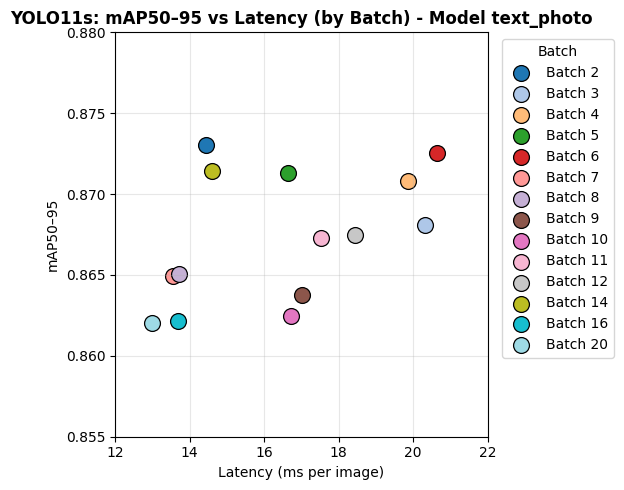

In [210]:
plot_yolo11s_map_vs_latency(df_yolo_text_photo, 12, 22, 0.855, 0.88)

C:\Users\danie\AppData\Local\Temp\ipykernel_16316\531294971.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("tab20", len(unique_batches))


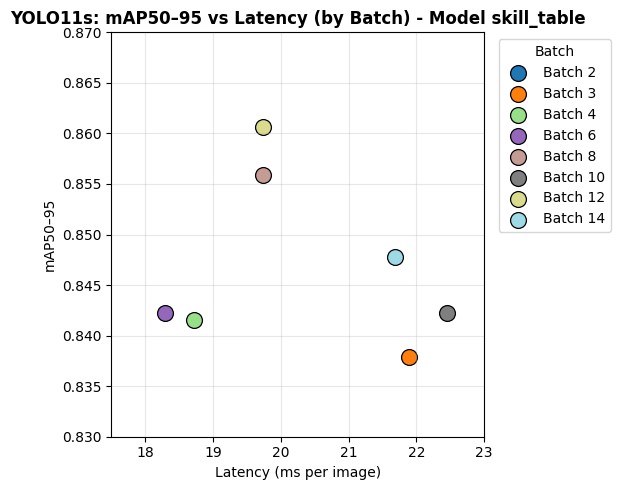

In [212]:
plot_yolo11s_map_vs_latency(df_yolo_skill_table, 17.5, 23, 0.83, 0.87)

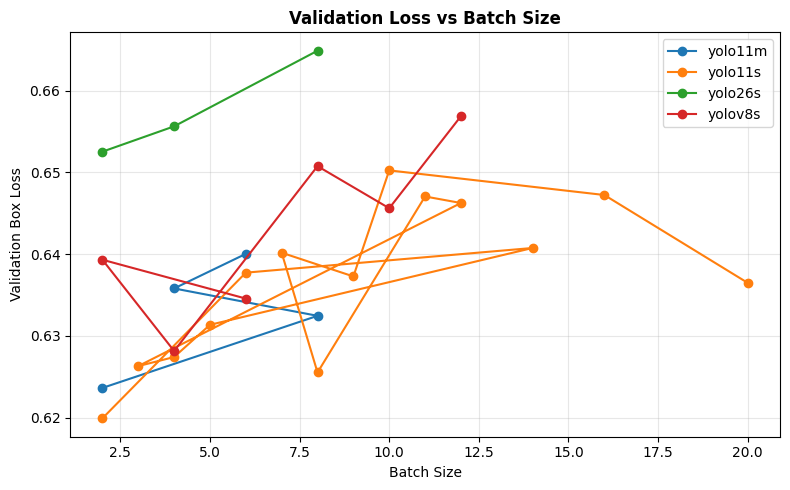

In [111]:
def plot_loss_analysis(df):

    plt.figure(figsize=(8,5))

    for version, group in df.groupby("yolo_version"):
        plt.plot(
            group["batch_config"],
            group["val_box_loss"],
            marker="o",
            label=version
        )

    plt.xlabel("Batch Size")
    plt.ylabel("Validation Box Loss")
    plt.title("Validation Loss vs Batch Size", weight="bold")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_loss_analysis(df_yolo_text_photo)

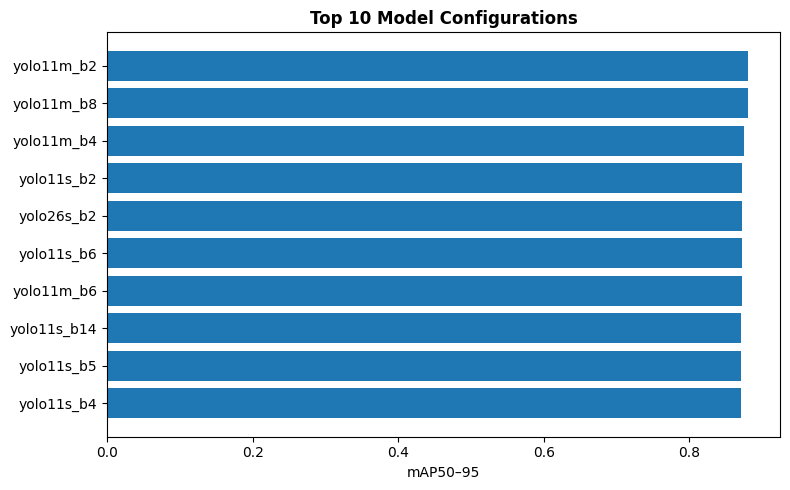

In [198]:
def plot_top_models(df):

    df_sorted = df.sort_values("mAP50-95", ascending=False).head(10)

    plt.figure(figsize=(8,5))

    plt.barh(
        df_sorted["yolo_version"] + "_b" + df_sorted["batch_config"].astype(str),
        df_sorted["mAP50-95"]
    )

    plt.xlabel("mAP50–95")
    plt.title("Top 10 Model Configurations", weight="bold")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

plot_top_models(df_yolo_text_photo)


#### 1.2.4 YOLO graphs related to epochs

In [207]:
def plot_map50_over_epochs(df):
    """
    Plota a evolução do mAP50 ao longo das epochs.
    """

    plt.figure(figsize=(5, 3.5))

    plt.plot(
        df["epoch"],
        df["metrics/mAP50-95(B)"],
        linewidth=2,
        color="blue"
    )

    plt.xlabel("Epoch")
    plt.ylabel("mAP50-95")
    plt.title("mAP50 Evolution of the Epochs - Model text_photo", weight="bold")

    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


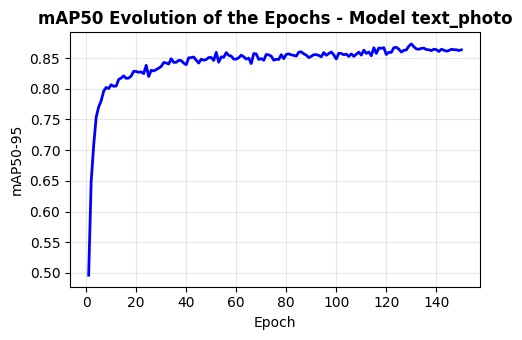

In [208]:
plot_map50_over_epochs(df_epochs_text_photo)


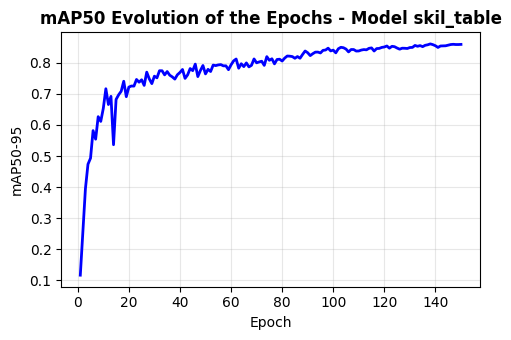

In [206]:
plot_map50_over_epochs(df_epochs_skill_table)
